In [1]:
import yaml
import warnings
import sys

import pandas as pd
import numpy as np
import matplotlib
import matplotlib.pyplot as pl
import seaborn as sns
import PyComplexHeatmap as pch
from pathlib import Path
from tqdm.auto import tqdm

# make figures paper quality
matplotlib.rcParams['pdf.fonttype'] = 42
matplotlib.rcParams['ps.fonttype'] = 42
matplotlib.rcParams['font.family'] = 'sans-serif'
matplotlib.rcParams['font.sans-serif'] = 'Arial'

# Remove warning, we like to live dangerously
warnings.filterwarnings("ignore")

# load functions from ../utils
sys.path.append('../utils')
from utils import get_nnmd

# Get config settings
with open('../configuration/config.yaml', "r") as file:
    config = yaml.load(file, Loader=yaml.FullLoader)
cell_line_dict=config['cell_lines']

In [2]:
# counts
df = pd.read_csv(Path(config['TEMPDIR']) / 'pooled_screen_1/pooled_screen_1_counts.csv', index_col=0)
# essential genes
essential = pd.read_csv("../resources/bagel_supplement/CEGv2.txt", sep='\t', index_col=0)
non_essential = pd.read_csv("../resources/bagel_supplement/NEGv1.txt", sep='\t', index_col=0)

# Gscreend Fernanda (gene-wise)

In [2]:
tabs = {}
for i in [1,2,3]:
    tabs[cell_line_dict[i]] = pd.read_excel(f'../resources/fernanda_gscreend/gscreend_results_Sym101_0{i}.xlsx')

In [3]:
tabs['H1975']

,Gene,FDR_TP1,pvalue_TP1,LFC_TP1,Diffexpress_TP1,FDR_TP2,pvalue_TP2,LFC_TP2,Diffexpress_TP2,FDR_TP3,...,LFC_TP4,Diffexpress_TP4,FDR_TP5,pvalue_TP5,LFC_TP5,Diffexpress_TP5,FDR_TP6,pvalue_TP6,LFC_TP6,Diffexpress_TP6
0,AATBC,1.0,1.000000,0.089637,NO,1.0,1.000000,0.128774,NO,1.000000,...,0.188654,NO,1.0,1.000000,0.187648,NO,1.000000,1.000000,0.224566,NO
1,ACKR2,1.0,0.845879,0.007570,NO,1.0,0.936649,0.003993,NO,1.000000,...,0.068886,NO,1.0,1.000000,0.125832,NO,1.000000,1.000000,0.110799,NO
2,ACTA2-AS1,1.0,1.000000,0.094964,NO,1.0,1.000000,0.145627,NO,1.000000,...,0.269447,NO,1.0,1.000000,0.281698,NO,1.000000,1.000000,0.308602,NO
3,ACTB,0.0,0.000000,-0.589395,DOWN,0.0,0.000000,-1.005634,DOWN,0.000000,...,-1.655178,DOWN,0.0,0.000000,-1.733700,DOWN,0.000000,0.000000,-1.921871,DOWN
4,ACTG1,0.0,0.000000,-0.845664,DOWN,0.0,0.000000,-1.334491,DOWN,0.000000,...,-2.163782,DOWN,0.0,0.000000,-2.404333,DOWN,0.000000,0.000000,-2.751955,DOWN
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
729,ZNF728,1.0,1.000000,-0.049971,NO,1.0,1.000000,0.012667,NO,1.000000,...,0.109417,NO,1.0,1.000000,0.112433,NO,1.000000,1.000000,0.159111,NO
730,ZNF93,1.0,1.000000,-0.001196,NO,1.0,0.943290,-0.050000,NO,1.000000,...,-0.286134,NO,1.0,0.537296,-0.384417,NO,1.000000,0.472071,-0.450325,NO
731,ZNHIT2,1.0,1.000000,-0.317678,NO,1.0,1.000000,-0.258504,NO,1.000000,...,-0.154158,NO,1.0,1.000000,-0.158300,NO,1.000000,1.000000,-0.104442,NO
732,ZRANB2,0.0,0.000000,-0.430054,DOWN,0.0,0.000000,-0.403624,DOWN,0.058824,...,-0.508717,NO,1.0,0.286444,-0.593669,NO,0.704605,0.182391,-0.682940,NO


In [5]:
for cell_line in cell_line_dict.values():

    groups = ['DOWN', 'NO', 'UP']

    tab = tabs[cell_line]
    source = []
    target = []
    label = groups.copy()
    value = []
    pos = []
    for layer in [1,2,3,4,5]:
        for i, xi in enumerate(groups):
            label.append(xi)
            pos.append(layer)
            for j, xj in enumerate(groups):
                source.append(i + 3 * layer)
                target.append(j + 3 * (layer + 1))
                # transition
                v = ((tab[f'Diffexpress_TP{layer}'] == xi) & (tab[f'Diffexpress_TP{layer+1}'] == xj)).sum()
                value.append(v)
    label.extend(groups)
    pos.extend([6, 6, 6])
    color = ['blue' if x == 'UP' else 'red' if x == 'DOWN' else 'gray' for x in label]

    label = [x.replace('NO', 'Not significant') for x in label]
    
    import plotly.graph_objects as go

    link = dict(source = source, target = target, value = value)
    data = go.Sankey(link = link, node = dict(
        x = pos,
        pad = 15,
        thickness = 20,
        line = dict(color = "black", width = 0.5),
        label = label,
        color = color
        ),)

    fig = go.Figure(data)
    fig.update_layout(
        autosize=False,
        width=800,
        height=300,
    )
    fig.show()

## Compare with BAGEL2 results

In [21]:
file = '../results/tables/pooled_screen_1_bagel_pr_gene.tsv'
df = pd.read_table(file, index_col=0, header=[0,1,2])

In [22]:
df

alllines                                                     \
            alltimes                            TP5TP6                    
                  BF Recall Precision    FDR        BF Recall Precision   
Gene                                                                      
RAN         9969.672  0.005     1.000  0.000  5798.778  0.005     1.000   
FBL         5449.419  0.005     1.000  0.000  3394.553  0.005     1.000   
EIF4A1      4661.117  0.005     1.000  0.000  2410.584  0.010     1.000   
HNRNPA1     4135.492  0.005     1.000  0.000  2185.951  0.010     1.000   
SNHG16      3811.712  0.005     1.000  0.000  2233.446  0.010     1.000   
...              ...    ...       ...    ...       ...    ...       ...   
PCAT1      -1172.589  1.000     0.865  0.135  -553.261  1.000     0.865   
PCBP4      -1203.189  1.000     0.865  0.135  -600.722  1.000     0.865   
BIN1       -1436.490  1.000     0.865  0.135  -639.859  1.000     0.865   
HOTAIRM1   -1581.295  1.000     0.865  0.135  -800.927  1.000     0.865   
NT_Control -2505.494  1.000     0.865  0.135 -1424.679  1.000     0.865   

                       A549         ...     H1299            H1975         \
                   alltimes         ...    TP5TP6         alltimes          
              FDR        BF Recall  ... Precision    FDR        BF Recall   
Gene                                ...                                     
RAN         0.000  2046.360  0.005  ...     1.000  0.000  3094.169  0.005   
FBL         0.000   586.054  0.065  ...     1.000  0.000  2575.971  0.005   
EIF4A1      0.000  1225.385  0.005  ...     1.000  0.000  1279.115  0.005   
HNRNPA1     0.000  1146.395  0.005  ...     1.000  0.000   890.383  0.020   
SNHG16      0.000  1001.866  0.015  ...     1.000  0.000   906.484  0.020   
...           ...       ...    ...  ...       ...    ...       ...    ...   
PCAT1       0.135  -340.449  1.000  ...     0.865  0.135  -447.549  1.000   
PCBP4       0.135  -368.308  1.000  ...     0.865  0.135  -479.808  1.000   
BIN1        0.135  -344.503  1.000  ...     0.865  0.135  -618.303  1.000   
HOTAIRM1    0.135  -474.106  1.000  ...     0.865  0.135  -605.877  1.000   
NT_Control  0.135  -516.507  1.000  ...     0.865  0.135 -1100.500  1.000   

                                                               
                               TP5TP6                          
           Precision    FDR        BF Recall Precision    FDR  
Gene                                                           
RAN            1.000  0.000  1322.864  0.005     1.000  0.000  
FBL            1.000  0.000  1260.358  0.005     1.000  0.000  
EIF4A1         1.000  0.000   564.761  0.005     1.000  0.000  
HNRNPA1        1.000  0.000   428.998  0.015     1.000  0.000  
SNHG16         1.000  0.000   471.557  0.015     1.000  0.000  
...              ...    ...       ...    ...       ...    ...  
PCAT1          0.865  0.135  -186.700  1.000     0.865  0.135  
PCBP4          0.865  0.135  -206.198  1.000     0.865  0.135  
BIN1           0.865  0.135  -276.360  1.000     0.865  0.135  
HOTAIRM1       0.865  0.135  -248.370  1.000     0.865  0.135  
NT_Control     0.865  0.135  -542.439  1.000     0.865  0.135  

[734 rows x 32 columns]

In [51]:
cell_line = 'H1299'
tab = tabs[cell_line].set_index('Gene')
sdf = df.loc[:, (cell_line, 'TP5TP6', slice(None, None, None))]  # get all entries for cell_line TP5TP6
# drop column multiindex levels 0 and 1 for sdf
sdf.columns = sdf.columns.droplevel([0,1])

In [52]:
total_df = pd.concat([sdf, tab], axis=1, join='inner')

# Annotate essentiallity based on original Bagel list
essential = pd.read_csv("/home/peidli/utils/bagel/CEGv2.txt", sep='\t', index_col=0)
non_essential = pd.read_csv("/home/peidli/utils/bagel/NEGv1.txt", sep='\t', index_col=0)
total_df['essentiality'] = ['essential' if g in essential.index else 'non-essential' if g in non_essential.index else 'unknown' for g in total_df.index]

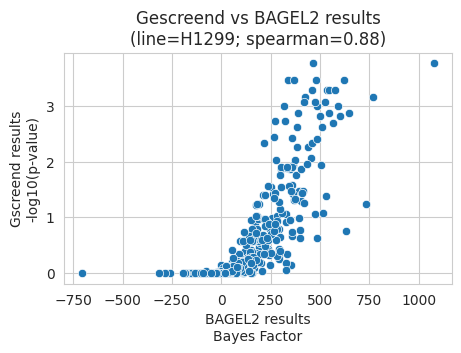

In [54]:
with sns.axes_style('whitegrid'):
    fig, ax = pl.subplots(figsize=(5,3))
total_df['score_TP6'] =-np.log10(total_df['pvalue_TP6'])
sns.scatterplot(data=total_df, x='BF', y='score_TP6')
ax.set_xlabel('BAGEL2 results\nBayes Factor')
ax.set_ylabel('Gscreend results\n-log10(p-value)')
# ax.set_xlim(-300, 300)
spearman = total_df[['BF', 'score_TP6']].corr(method='spearman').iloc[0,1]
ax.set_title(f'Gescreend vs BAGEL2 results\n(line={cell_line}; spearman=%.2f)' % spearman)
pl.show()

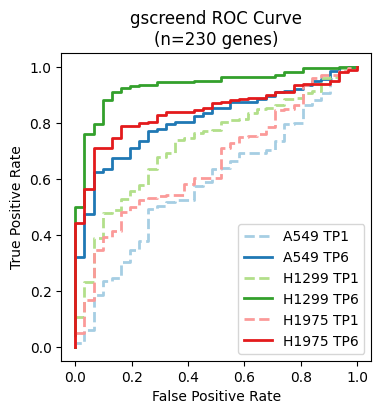

In [39]:
from sklearn.metrics import roc_curve
from matplotlib.cm import get_cmap

with sns.axes_style('whitegrid'):
    pl.figure(figsize=(4,4))
cmap = get_cmap('Paired')

i = 0
for line in ['A549', 'H1299', 'H1975']:
    for time in ['TP1', 'TP6']:
        sdf = tabs[line].set_index('Gene')
        sdf['essentiality'] = ['essential' if g in essential.index else 'non-essential' if g in non_essential.index else 'unknown' for g in sdf.index]

        mask = sdf.essentiality!='unknown'
        fpr, tpr, thresholds = roc_curve(sdf[mask].essentiality=='essential', -sdf[mask][f'LFC_{time}'])
        
        style ='--' if time=='TP1' else '-'
        color = cmap(i)
        pl.plot(fpr, tpr, label=f'{line} {time}', linewidth=2, linestyle=style, color=color)
        i += 1
pl.legend()
pl.xlabel('False Positive Rate')
pl.ylabel('True Positive Rate')
pl.title(f'gscreend ROC Curve\n(n={(sdf.essentiality!="unknown").sum()} genes)')
pl.show()


# Bagel2 (gene-wise)

In [11]:
filtered = True

name = '_filtered' if filtered else ''
# get counts
df = pd.read_table(f'../results/bagel2/pooled_screen_1_counts{name}_bagel_pr_gene.tsv', index_col=0, header=[0,1,2])
# Annotate essentiallity based on original Bagel list
df['essentiality'] = ['essential' if g in essential.index else 'non-essential' if g in non_essential.index else 'unknown' for g in df.index]

In [14]:
sdf

,BF,Recall,Precision,FDR,essentiality
Gene,,,,,
RAN,9335.479,0.005,1.000,0.000,essential
FBL,3943.980,0.005,1.000,0.000,unknown
EIF4A1,3224.351,0.005,1.000,0.000,unknown
HNRNPA1,2964.005,0.005,1.000,0.000,unknown
RPS16,2917.580,0.010,1.000,0.000,essential
...,...,...,...,...,...
BIN1,-527.879,1.000,0.865,0.135,unknown
HOTAIRM1,-555.284,1.000,0.865,0.135,unknown
PCAT1,-557.794,1.000,0.865,0.135,unknown


essential vs. non-essential: t-test independent samples, P_val:6.964e-04 t=3.438e+00


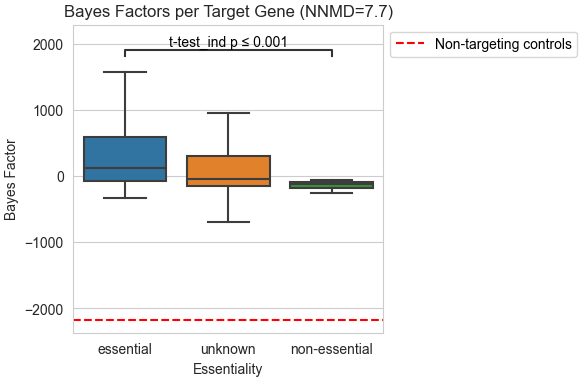

In [20]:
sdf = df.loc[:, ('alllines', 'alltimes', slice(None, None, None))]  # get all entries
# now remove the multi-index
sdf.columns = sdf.columns.droplevel([0,1])
sdf['essentiality'] = df['essentiality']

with sns.axes_style('whitegrid'):
    fig, ax = pl.subplots(1, 1, figsize=(4,4))
sns.boxplot(data=sdf, x='essentiality', y='BF', showfliers=False)
pl.axhline(sdf.loc['NT_Control', 'BF'], color='r', linestyle='--', label='Non-targeting controls')
pl.legend()
# move legend outside
pl.legend(loc='upper left', bbox_to_anchor=(1, 1))
pl.ylabel('Bayes Factor')
pl.xlabel('Essentiality')
nnmd = get_nnmd(sdf, score_column='BF')
pl.title(f'Bayes Factors per Target Gene (NNMD={np.round(nnmd,1)})', fontsize=12)

from statannotations.Annotator import Annotator
annotator = Annotator(ax, [('essential', 'non-essential')], data=sdf, x='essentiality', y='BF')
annotator.configure(test='t-test_ind', text_format='simple', loc='inside')
annotator.apply_and_annotate()

pl.savefig(f'../results/bagel2/bayes_factor_essentiality{name}.pdf', bbox_inches='tight', dpi=300)
pl.show()

In [21]:
# BF vs guide score
cts = pd.read_csv(Path(config['TEMPDIR']) / f'pooled_screen_1/pooled_screen_1_counts{name}.csv', index_col=0)

sample_names = np.sort(cts.columns[12:])
pools = ['Sym-pool-1-3', 'Sym-pool-1-1', 'Sym-pool-1-2']
pools = np.sort(pools)
sample_names_wo_pools = [x for x in sample_names if not any([p in x for p in pools])]
controls = [x for x in cts.index if 'control' in x.lower()]

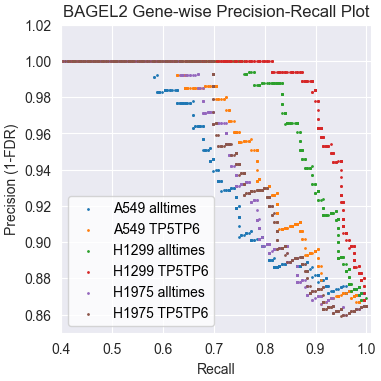

In [22]:
with sns.axes_style('darkgrid'):
    fig, ax = pl.subplots(figsize=(4,4))
selection = ['alllines', 'alltimes']
for line in ['A549', 'H1299', 'H1975']:
    for time in ['alltimes', 'TP5TP6']:
        pl.scatter(df[line, time, 'Recall'], df[line, time, 'Precision'], 
                   label=f'{line} {time}', 
                   s=1)
pl.xlim(0.4,1.01)
pl.ylim(0.85,1.02)
pl.xlabel('Recall')
pl.ylabel('Precision (1-FDR)')
pl.legend()
pl.title('BAGEL2 Gene-wise Precision-Recall Plot')
pl.savefig(f'../results/bagel2/bagel2_precision_recall{name}.pdf', bbox_inches='tight', dpi=300)
pl.show()

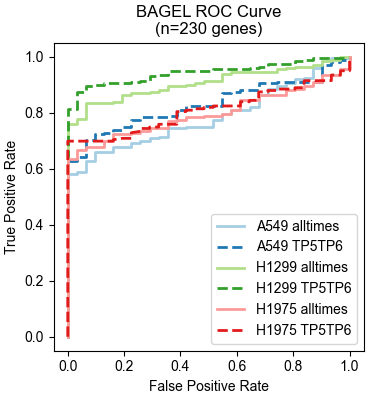

In [23]:
from sklearn.metrics import roc_curve
from matplotlib.cm import get_cmap

with sns.axes_style('whitegrid'):
    pl.figure(figsize=(4,4))
cmap = get_cmap('Paired')

i = 0
for line in ['A549', 'H1299', 'H1975']:
    for time in ['alltimes', 'TP5TP6']:
        sdf = df.loc[:, (line, time, slice(None, None, None))]  # get all entries
        # now remove the multi-index
        sdf.columns = sdf.columns.droplevel([0,1])
        sdf['essentiality'] = df['essentiality']

        mask = sdf.essentiality!='unknown'
        fpr, tpr, thresholds = roc_curve(sdf[mask].essentiality=='essential', sdf[mask].BF)
        
        style ='-' if time=='alltimes' else '--'
        color = cmap(i)
        pl.plot(fpr, tpr, label=f'{line} {time}', linewidth=2, linestyle=style, color=color)
        i += 1
pl.legend()
pl.xlabel('False Positive Rate')
pl.ylabel('True Positive Rate')
pl.title(f'BAGEL ROC Curve\n(n={(sdf.essentiality!="unknown").sum()} genes)')
pl.savefig(f'../results/bagel2/bagel2_roc{name}.pdf', bbox_inches='tight', dpi=300)
pl.show()


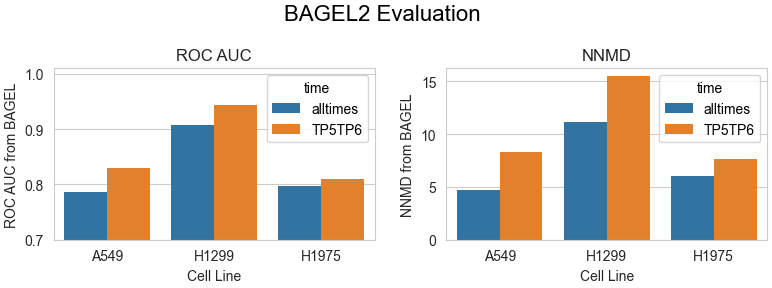

In [34]:
# AUC scores
from sklearn.metrics import roc_auc_score
aucs = {}
nnmds = {}
for line in ['A549', 'H1299', 'H1975']:
    for time in ['alltimes', 'TP5TP6']:
        sdf = df.loc[:, (line, time, slice(None, None, None))]  # get all entries
        # now remove the multi-index
        sdf.columns = sdf.columns.droplevel([0,1])
        sdf['essentiality'] = df['essentiality']

        mask = sdf.essentiality!='unknown'
        aucs[(line, time)] = roc_auc_score(sdf[mask].essentiality=='essential', sdf[mask].BF)
        nnmds[(line, time)] = get_nnmd(sdf, score_column='BF')
auc_df = pd.DataFrame(aucs, index=['AUC']).T.reset_index().rename(columns={'level_0':'line', 'level_1':'time'})
nnmd_df = pd.DataFrame(nnmds, index=['NNMD']).T.reset_index().rename(columns={'level_0':'line', 'level_1':'time'})

with sns.axes_style('whitegrid'):
    fig, axs = pl.subplots(1, 2, figsize=(4*2,3))
ax = axs[0]
sns.barplot(data=auc_df, x='line', y='AUC', hue='time', ax=ax)
ax.set_xlabel('Cell Line')
ax.set_ylabel('ROC AUC from BAGEL')
ax.set_ylim(0.7,1.01)
ax.set_title('ROC AUC')

ax = axs[1]
sns.barplot(data=nnmd_df, x='line', y='NNMD', hue='time', ax=ax)
ax.set_xlabel('Cell Line')
ax.set_ylabel('NNMD from BAGEL')
# ax.set_ylim(0.7,1.01)
ax.set_title('NNMD')

pl.suptitle('BAGEL2 Evaluation', fontsize=16)
pl.tight_layout()

pl.savefig(f'../results/bagel2/bagel2_eval{name}.pdf', bbox_inches='tight', dpi=300)
pl.show()

### Comparison with previous Cas9 data

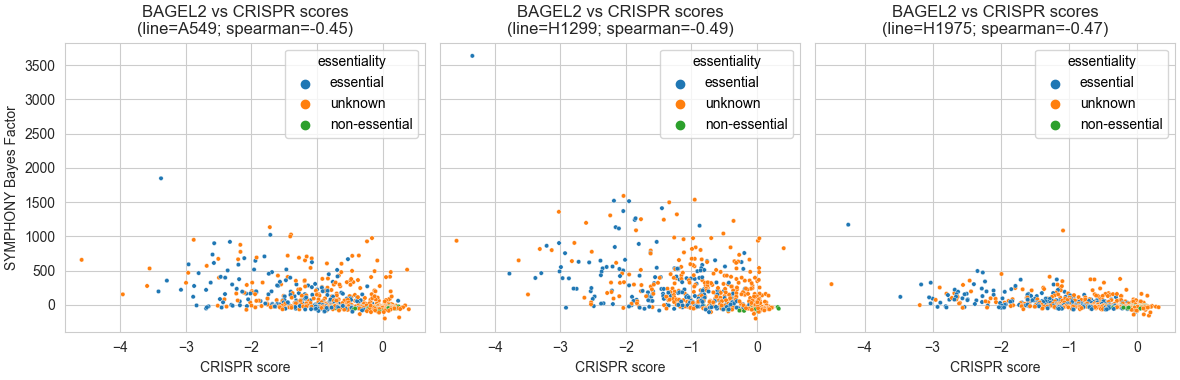

In [51]:
with sns.axes_style('whitegrid'):
    fig, axs = pl.subplots(1, 3, figsize=(4*3,4), sharey=True)
for i, line in enumerate(['A549', 'H1299', 'H1975']):
    ax = axs[i]
    sdf = df.loc[:, (line, 'TP5TP6', slice(None, None, None))]  # get all entries
    # now remove the multi-index
    sdf.columns = sdf.columns.droplevel([0,1])

    # Annotate
    sdf['essentiality'] = df['essentiality']
    sdf['guide_score'] = cts[['Guide_Score', 'Gene']].groupby('Gene').mean().loc[sdf.index, 'Guide_Score']
    gene_data = pd.read_csv('../resources/symp_101_final_gene_list.csv', index_col=0)
    sdf = pd.merge(sdf, gene_data, left_index=True, right_index=True, how='left')
    
    cl_name = f'NCI{line}' if line!='A549' else line
    sns.scatterplot(data=sdf, y='BF', x=f'{cl_name}_Crs', hue='essentiality', s=10, ax=ax)
    # add spearman correlation
    spearman = sdf[['BF', f'{cl_name}_Crs']].corr(method='spearman').iloc[0,1]
    ax.set_xlabel('CRISPR score')
    ax.set_ylabel('SYMPHONY Bayes Factor')
    ax.set_title(f'BAGEL2 vs CRISPR scores\n(line={line}; spearman=%.2f)' % spearman)
pl.tight_layout()
pl.savefig(f'../results/bagel2/bagel2_vs_crispr{name}.pdf', bbox_inches='tight', dpi=300)
pl.show()

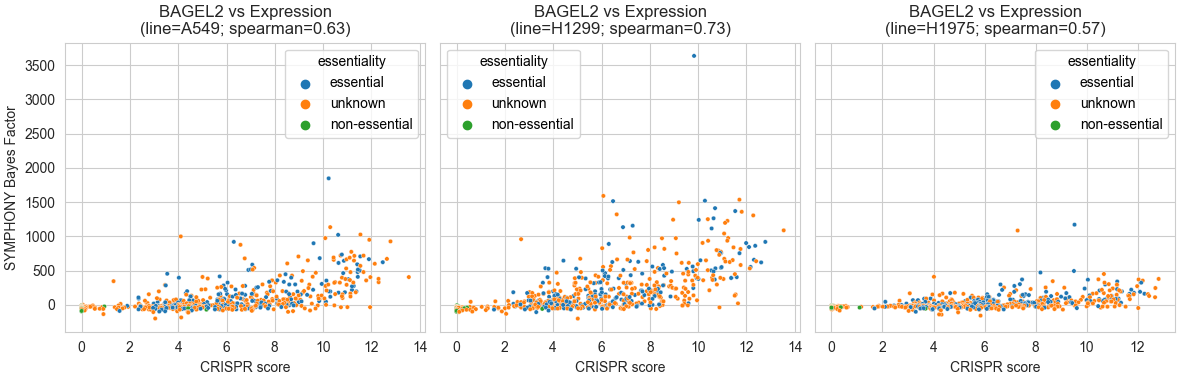

In [52]:
with sns.axes_style('whitegrid'):
    fig, axs = pl.subplots(1, 3, figsize=(4*3,4), sharey=True)
for i, line in enumerate(['A549', 'H1299', 'H1975']):
    ax = axs[i]
    sdf = df.loc[:, (line, 'TP5TP6', slice(None, None, None))]  # get all entries
    # now remove the multi-index
    sdf.columns = sdf.columns.droplevel([0,1])

    # Annotate
    sdf['essentiality'] = df['essentiality']
    sdf['guide_score'] = cts[['Guide_Score', 'Gene']].groupby('Gene').mean().loc[sdf.index, 'Guide_Score']
    gene_data = pd.read_csv('../resources/symp_101_final_gene_list.csv', index_col=0)
    sdf = pd.merge(sdf, gene_data, left_index=True, right_index=True, how='left')
    
    cl_name = f'NCI{line}' if line!='A549' else line
    sns.scatterplot(data=sdf, y='BF', x=f'{cl_name}_Exp', hue='essentiality', s=10, ax=ax)
    # add spearman correlation
    spearman = sdf[['BF', f'{cl_name}_Exp']].corr(method='spearman').iloc[0,1]
    ax.set_xlabel('CRISPR score')
    ax.set_ylabel('SYMPHONY Bayes Factor')
    ax.set_title(f'BAGEL2 vs Expression\n(line={line}; spearman=%.2f)' % spearman)
pl.tight_layout()
pl.savefig(f'../results/bagel2/bagel2_vs_depmap_expression{name}.pdf', bbox_inches='tight', dpi=300)
pl.show()

### Correlation of BFs across lines

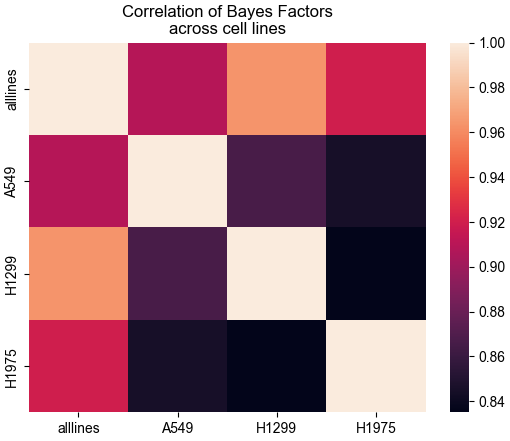

In [56]:
sdf = df.xs('BF', level=2, axis=1).xs('alltimes', level=1, axis=1)
sns.heatmap(sdf.corr())
pl.title('Correlation of Bayes Factors\nacross cell lines')
pl.savefig(f'../results/bagel2/bagel2_line_correlation{name}.pdf', bbox_inches='tight', dpi=300)
pl.show()

# MAGeCK

## Guide Ranking, Filtering

- Look for highest MAGeCK score and absLFC across cell lines
- Set threshold for filtering to XXth percentile of max score in NT guides
- Mark all guides with less score than threshold as "filtered out"

In [6]:
all_guide_rankings = pd.concat({cell_line: pd.read_csv(f'../results/mageck/summaries/{cell_line}/gene_pooled_screen_1_counts_mageck.sgrna_summary.txt', sep='\t', index_col=0) for cell_line in cell_line_dict.values()}, axis=1)
# aggregate
all_guide_rankings[('summary', 'max_score')] = all_guide_rankings.loc[:, (slice(None), 'score')].max(axis=1)
all_guide_rankings[('summary', 'mean_score')] = all_guide_rankings.loc[:, (slice(None), 'score')].mean(axis=1)
all_guide_rankings[('summary', 'min_score')] = all_guide_rankings.loc[:, (slice(None), 'score')].min(axis=1)
all_guide_rankings[('summary', 'max_LFC')] = all_guide_rankings.loc[:, (slice(None), 'LFC')].max(axis=1)
all_guide_rankings[('summary', 'mean_LFC')] = all_guide_rankings.loc[:, (slice(None), 'LFC')].mean(axis=1)
all_guide_rankings[('summary', 'min_LFC')] = all_guide_rankings.loc[:, (slice(None), 'LFC')].min(axis=1)
all_guide_rankings[('summary', 'absmax_LFC')] = np.abs(all_guide_rankings.loc[:, (slice(None), 'LFC')]).max(axis=1)
all_guide_rankings[('summary', 'is_control')] = all_guide_rankings.index.str.contains('Control').astype(str)

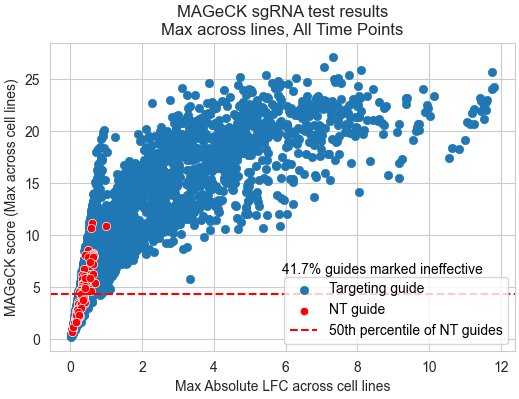

In [8]:
data = all_guide_rankings.loc[:, 'summary']
data_control = data[(data.is_control=='True')]

y_key = 'max_score'
p = 50

with sns.axes_style('whitegrid'):
    fig, ax = pl.subplots(figsize=(6,4))

sns.scatterplot(data=data, x='absmax_LFC', y=y_key, edgecolor=None, label='Targeting guide')
sns.scatterplot(data=data_control, x='absmax_LFC', y=y_key, color='red', label='NT guide')

tresh = np.percentile(data_control[y_key], p)
pl.axhline(tresh, color='r', linestyle='--', label=f'{p}th percentile of NT guides')
percent_removed = ((data[y_key]<tresh) & (data.is_control=='False')).mean()
pl.text(0.5, 0.25, f'{percent_removed:.1%} guides marked ineffective', transform=pl.gca().transAxes)
pl.title('MAGeCK sgRNA test results\nMax across lines, All Time Points')
pl.ylabel('MAGeCK score (Max across cell lines)')
pl.xlabel('Max Absolute LFC across cell lines')
pl.legend()
pl.show()

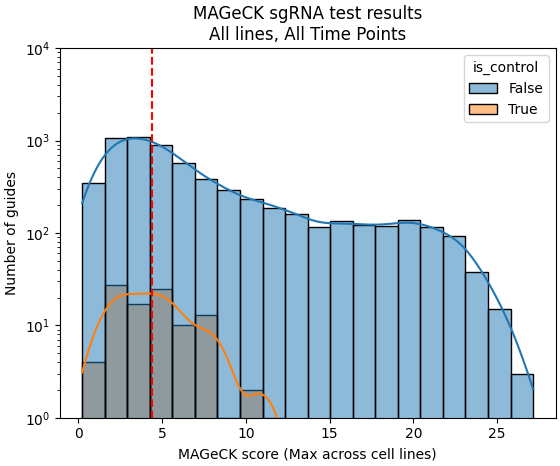

In [5]:
sns.histplot(data=data, x='max_score', bins=20, kde=True, hue='is_control')
pl.axvline(tresh, color='r', linestyle='--', label=f'{p}th percentile of controls')
pl.yscale('log')
pl.ylim(1, 1e4)
pl.ylabel('Number of guides')
pl.xlabel('MAGeCK score (Max across cell lines)')
pl.title('MAGeCK sgRNA test results\nAll lines, All Time Points')
pl.show()

In [6]:
# annotate
all_guide_rankings[('summary', 'is_working')] = all_guide_rankings.loc[:, 'summary'].max_score>tresh

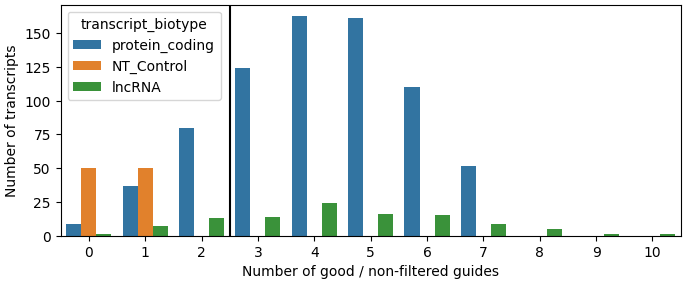

In [90]:
# How many guides are marked per target?
data = all_guide_rankings.loc[:, 'summary']
# add infos
df = pd.read_csv(Path(config['TEMPDIR']) / 'pooled_screen_1/pooled_screen_1_counts.csv', index_col=0)
for col in ['Gene', 'Transcript_ID', 'transcript_biotype', 'Region']:
    data[col] = df.loc[data.index, col]
# counting
sdf = data.groupby(['Transcript_ID', 'transcript_biotype'], observed=False).sum().is_working.reset_index()
sdf = sdf[(sdf.transcript_biotype.isin(['protein_coding', 'lncRNA', 'NT_Control']))]
sdf.rename(columns={'is_working':'good_guides_count'}, inplace=True)

pl.figure(figsize=(8,3))
sns.barplot(data=sdf.value_counts(['transcript_biotype', 'good_guides_count']).reset_index(),
            x='good_guides_count', y=0, hue='transcript_biotype')
pl.xlabel('Number of good / non-filtered guides')
pl.ylabel('Number of transcripts')
pl.axvline(2.5, color='k')
pl.show()

In [93]:
# filtering would remove too many guides for these target, so we enforce keeping at least 3 guides
N = 3
key = 'keep_flag'
too_few = sdf.loc[sdf.good_guides_count<N, 'Transcript_ID']
print(len(too_few))

data = all_guide_rankings.loc[:, 'summary']
# add infos
df = pd.read_csv(Path(config['TEMPDIR']) / 'pooled_screen_1/pooled_screen_1_counts.csv', index_col=0)
for col in ['Gene', 'Transcript_ID', 'transcript_biotype', 'Region']:
    data[col] = df.loc[data.index, col]
keep = data[data.Transcript_ID.isin(too_few)].groupby('Transcript_ID').max_score.nlargest(N).index.get_level_values(1)
all_guide_rankings.loc[:, ('summary', key)] = all_guide_rankings.loc[:, ('summary', 'is_working')].copy()
all_guide_rankings.loc[df.loc[all_guide_rankings.index].Transcript_ID.isin(too_few), ('summary', key)] = False
all_guide_rankings.loc[keep, ('summary', key)] = True

247


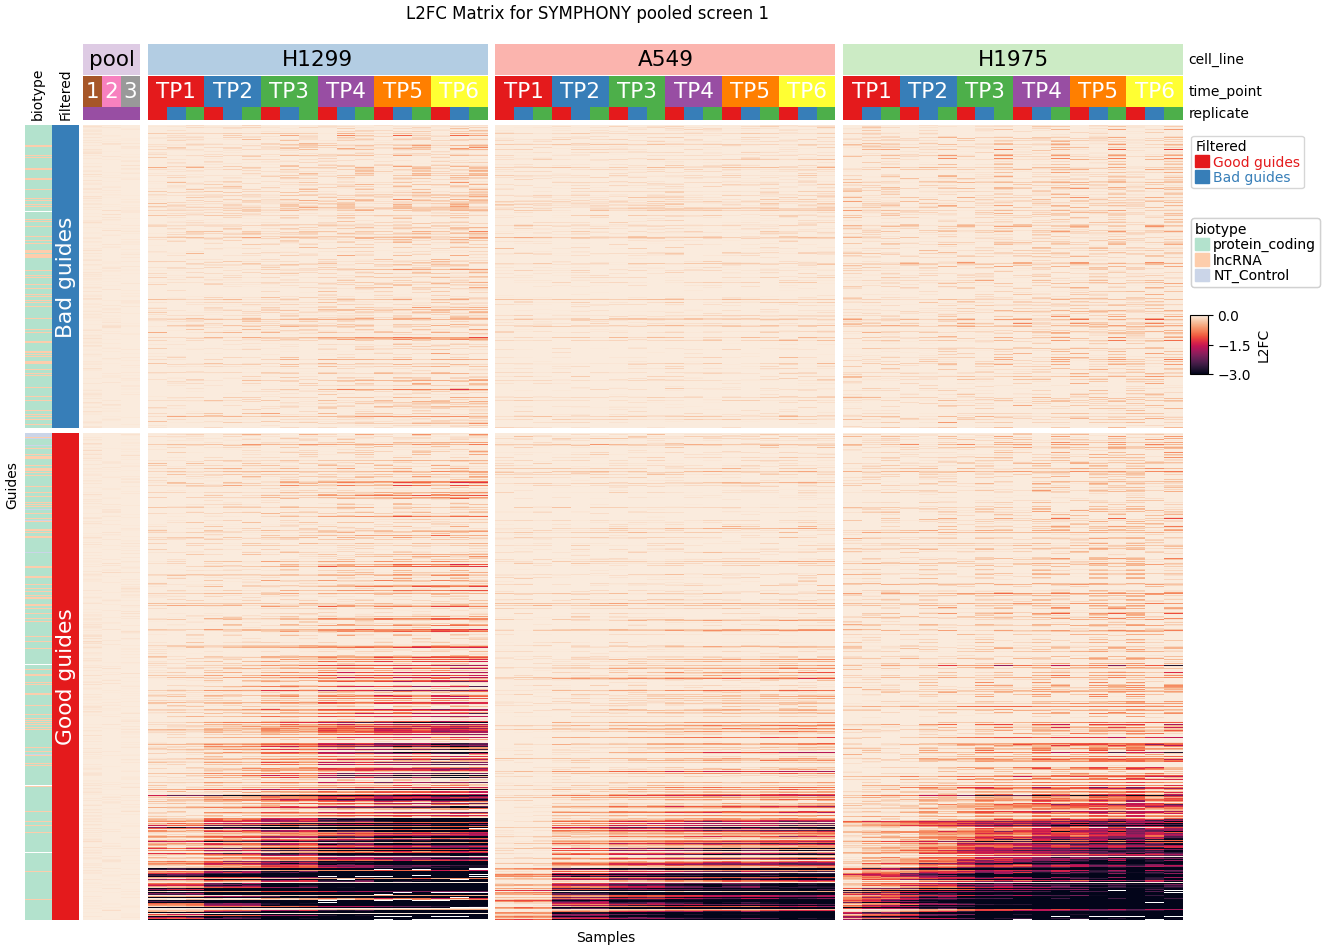

In [95]:
# visualize in heatmap
df = pd.read_csv(Path(config['TEMPDIR']) / 'pooled_screen_1/pooled_screen_1_counts.csv', index_col=0)

sample_names = np.sort(df.columns[12:])
pools = ['Sym-pool-1-3', 'Sym-pool-1-1', 'Sym-pool-1-2']
pools = np.sort(pools)
sample_names_wo_pools = [x for x in sample_names if not any([p in x for p in pools])]
controls = [x for x in df.index if 'control' in x.lower()]

# First I normalize for seq-depth by bringing all NT guides to the same count
target = df.loc[controls, sample_names_wo_pools].mean().mean()  # mean of NTs in control
ist = df.loc[controls, sample_names].mean()  # mean of NTs in all
norm_factor = target / ist  # make all NT mean counts equal to those in control
ndf = df.loc[:, sample_names] * norm_factor  # normalize

# Foldchange to Pool after seq-depth normalization based on NT depth
fc = (ndf.loc[:, sample_names].T / ndf.loc[:, pools].mean(axis=1)).T  # normalize to control (pools)
l2fc = np.log2(fc)
l2fc[l2fc==-np.infty] = None

import PyComplexHeatmap as pch
df['mean_l2fc'] = l2fc.mean(axis=1)
biotype = df.sort_values(['transcript_biotype', 'mean_l2fc']).transcript_biotype
biotype = biotype[~biotype.isin(['protein_coding_CDS_not_defined', 'retained_intron'])]
is_working = all_guide_rankings.loc[:, 'summary'].loc[data.index].sort_values(by=[key, 'max_score'])[key].astype(str).map({'True': 'Good guides', 'False': 'Bad guides'})

cell_line_dict_ = {f'0{x}': y for x, y in cell_line_dict.items()}
cell_line = pd.Series({x: x.split('-')[1] for x in sample_names}).replace(cell_line_dict_)
replicate = pd.Series({x: x.split('-')[2] for x in sample_names})
time_point = pd.Series({x: x.split('-')[3].split('_')[0] for x in sample_names})
col_order = pd.concat([cell_line, replicate, time_point], axis=1).sort_values([0, 2, 1]).index  # sort by time before replicate

# select and reorder
data = l2fc.loc[:, col_order]

top_ha = pch.HeatmapAnnotation(
    cell_line=pch.anno_simple(cell_line.loc[col_order], add_text=True, height=7, cmap='Pastel1'),
    time_point=pch.anno_simple(time_point.loc[col_order], add_text=True, height=7, cmap='Set1'),
    replicate=pch.anno_simple(replicate.loc[col_order], add_text=False),
    verbose=0, axis=1, plot_legend=False
)

left_ha = pch.HeatmapAnnotation(
    biotype=pch.anno_simple(biotype, legend=True, height=7, add_text=False, cmap='Pastel2'),
    Filtered=pch.anno_simple(is_working, legend=True, height=7, add_text=True, cmap='Set1'),
    verbose=0, axis=0, plot_legend=True
)

pl.figure(figsize=(15, 10))
cm = pch.ClusterMapPlotter(
    data=data, 
    left_annotation=left_ha, top_annotation=top_ha,
    row_cluster=False, col_cluster=False,
    row_split=is_working,
    col_split=cell_line.loc[col_order],
    col_split_gap=2, row_split_gap=1,
    label='beta', row_dendrogram=False, col_dendrogram=False,
    legend_gap=7, rasterized=True, cmap='rocket', vmin=-3, vmax=0,
    legend_kws=dict(label='L2FC'),
    xlabel="Samples", ylabel='Guides', legend_hpad=0,
    verbose=0
)
pl.suptitle('L2FC Matrix for SYMPHONY pooled screen 1', y=0.92)
# pl.savefig('../results/figures/count_matrix_l2fc_heatmap_simple.png', dpi=300)
# pl.savefig('../results/figures/count_matrix_l2fc_heatmap_simple.pdf', dpi=300)
pl.show()

In [96]:
# save results
# save results
all_guide_rankings.to_csv('../results/tables/pooled_screen_1_mageck_filtered_guides_v2.tsv', sep='\t')

## Gene Ranking

In [5]:
# The gene ranking results
filtered = True
name = '_filtered' if filtered else ''
gene_ranking = pd.read_csv(f'../results/mageck/alllines/gene_pooled_screen_1_counts{name}_mageck.gene_summary.txt', sep='\t', index_col=0)
gene_ranking = gene_ranking.reset_index().set_index(['id', 'num'])
gene_ranking.columns = pd.MultiIndex.from_arrays([
    [x.split('_vs_')[0] for x in gene_ranking.columns],
    [x.split('|')[1] for x in gene_ranking.columns],
    [x.split('|')[2] for x in gene_ranking.columns]
])

# For each sample, there are results for both pos and neg enrichment tests
# Result statistics include score, p-value, fdr, rank, "goodsgrna??", lfc
gene_ranking.head()

sym-01-01-TP6                                                      \
                     neg                                                 pos   
                   score   p-value       fdr rank goodsgrna     lfc    score   
id     num                                                                     
RAN    20   1.488200e-10  0.000005  0.000036    1        19 -4.9633  0.99998   
FBL    12   5.304500e-09  0.000005  0.000036    2        12 -6.6671  1.00000   
TMSB4X 7    9.309300e-08  0.000005  0.000036    3         7 -3.6477  1.00000   
SNHG16 10   3.598900e-07  0.000005  0.000036    4        10 -3.3369  1.00000   
EIF4A1 7    7.761900e-07  0.000005  0.000036    5         7 -4.4816  0.99999   

                              ... sym-03-03-TP6                         \
                              ...           neg                          
           p-value  fdr rank  ...           fdr rank goodsgrna     lfc   
id     num                    ...                                        
RAN    20      1.0  1.0  724  ...      0.000053    1        19 -2.3943   
FBL    12      1.0  1.0  733  ...      0.000134   25        10 -1.2671   
TMSB4X 7       1.0  1.0  732  ...      0.000053    6         7 -2.2624   
SNHG16 10      1.0  1.0  731  ...      0.000053    2        10 -2.1123   
EIF4A1 7       1.0  1.0  728  ...      0.000053    4         7 -3.9778   

                                                          
                pos                                       
              score  p-value  fdr rank goodsgrna     lfc  
id     num                                                
RAN    20   0.99972  0.99988  1.0  719         1 -2.3943  
FBL    12   0.32308  0.60271  1.0  358         2 -1.2671  
TMSB4X 7    0.99999  1.00000  1.0  732         0 -2.2624  
SNHG16 10   0.99998  1.00000  1.0  729         0 -2.1123  
EIF4A1 7    1.00000  1.00000  1.0  733         0 -3.9778  

[5 rows x 108 columns]

<Axes: ylabel='id-num'>

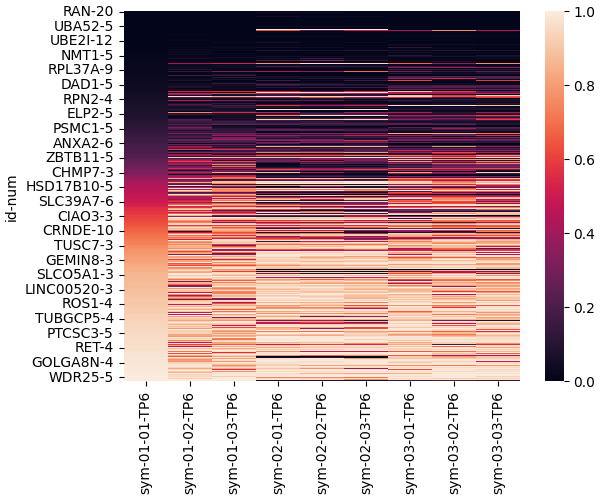

In [6]:
sns.heatmap(gene_ranking.T.loc[:, 'neg', 'score'].T)

<Axes: xlabel='lfc', ylabel='score'>

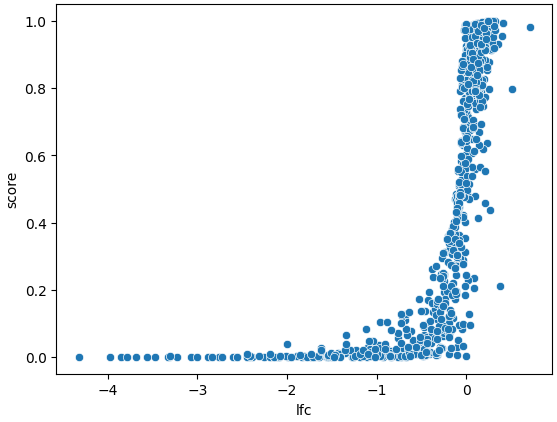

In [7]:
sns.scatterplot(data=gene_ranking.T.loc['sym-03-03-TP6', 'neg', :].T, x='lfc', y='score')

In [8]:
# unfiltered:
filtered = False
name = '_filtered' if filtered else ''
gene_ranking_ = pd.read_csv(f'../results/mageck/alllines/gene_pooled_screen_1_counts{name}_mageck.gene_summary.txt', sep='\t', index_col=0)
gene_ranking_ = gene_ranking_.reset_index().set_index(['id', 'num'])
gene_ranking_.columns = pd.MultiIndex.from_arrays([
    [x.split('_vs_')[0] for x in gene_ranking_.columns],
    [x.split('|')[1] for x in gene_ranking_.columns],
    [x.split('|')[2] for x in gene_ranking_.columns]
])

In [9]:
df_ = gene_ranking_.loc[:, (slice(None), 'neg', 'score')].mean(1).to_frame().rename(columns={0: 'MAGeCK_score'})
df_.index = df_.index.droplevel(1)
df = gene_ranking.loc[:, (slice(None), 'neg', 'score')].mean(1).to_frame().rename(columns={0: 'MAGeCK_score'})
df.index = df.index.droplevel(1)

In [10]:
tab = pd.merge(df, df_, left_index=True, right_index=True, suffixes=('_filtered', '_unfiltered'), how='outer')

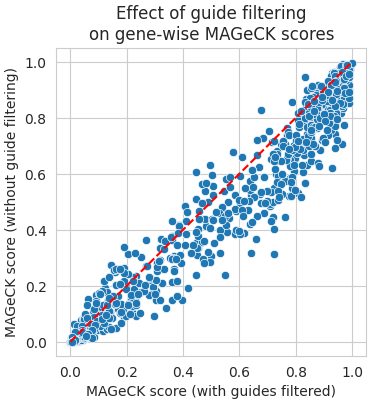

In [11]:
with sns.axes_style('whitegrid'):
    fig, ax = pl.subplots(figsize=(4,4))
sns.scatterplot(data=tab.fillna(0), x='MAGeCK_score_filtered', y='MAGeCK_score_unfiltered')
pl.xlabel('MAGeCK score (with guides filtered)')
pl.ylabel('MAGeCK score (without guide filtering)')
pl.title('Effect of guide filtering\non gene-wise MAGeCK scores')
pl.plot([0, 1], [0, 1], color='r', linestyle='--')
pl.show()

## Transcript ranking

In [91]:
# The gene ranking results
filtered = True
name = '_filtered' if filtered else ''
gene_ranking = pd.read_csv(f'../results/mageck/alllines/transcript_pooled_screen_1_counts{name}_mageck.gene_summary.txt', sep='\t', index_col=0)
gene_ranking = gene_ranking.reset_index().set_index(['id', 'num'])
gene_ranking.columns = pd.MultiIndex.from_arrays([
    [x.split('_vs_')[0] for x in gene_ranking.columns],
    [x.split('|')[1] for x in gene_ranking.columns],
    [x.split('|')[2] for x in gene_ranking.columns]
])

# For each sample, there are results for both pos and neg enrichment tests
# Result statistics include score, p-value, fdr, rank, "goodsgrna??", lfc
gene_ranking.head()

sym-01-01-TP6                                             \
                              neg                                              
                            score   p-value       fdr rank goodsgrna     lfc   
id              num                                                            
ENST00000451311 7        0.000029  0.000005  0.000007    1         7 -3.8822   
ENST00000293831 7        0.000095  0.000005  0.000007    2         7 -4.7127   
ENST00000579618 6        0.000138  0.000005  0.000007    3         5 -4.0365   
ENST00000230050 5        0.000202  0.000005  0.000007    4         5 -4.8973   
ENST00000251453 6        0.000333  0.000005  0.000007    5         6 -6.2830   

                                                  ... sym-03-03-TP6       \
                          pos                     ...           neg        
                        score  p-value  fdr rank  ...           fdr rank   
id              num                               ...                      
ENST00000451311 7    0.999970  1.00000  1.0  640  ...      0.000007   10   
ENST00000293831 7    0.998840  1.00000  1.0  632  ...      0.000007    2   
ENST00000579618 6    0.078182  0.40137  1.0   90  ...      0.000007   43   
ENST00000230050 5    0.999800  1.00000  1.0  639  ...      0.000007    4   
ENST00000251453 6    0.999050  1.00000  1.0  636  ...      0.000007   26   

                                                                             \
                                           pos                                
                    goodsgrna     lfc    score  p-value  fdr rank goodsgrna   
id              num                                                           
ENST00000451311 7           7 -2.6592  0.99911  1.00000  1.0  634         0   
ENST00000293831 7           7 -4.3895  0.99966  1.00000  1.0  636         0   
ENST00000579618 6           4 -2.0059  0.50398  0.99995  1.0  326         0   
ENST00000230050 5           5 -4.7399  0.99968  1.00000  1.0  638         0   
ENST00000251453 6           6 -3.7407  0.99489  1.00000  1.0  620         0   

                             
                             
                        lfc  
id              num          
ENST00000451311 7   -2.6592  
ENST00000293831 7   -4.3895  
ENST00000579618 6   -2.0059  
ENST00000230050 5   -4.7399  
ENST00000251453 6   -3.7407  

[5 rows x 108 columns]

<Axes: ylabel='id-num'>

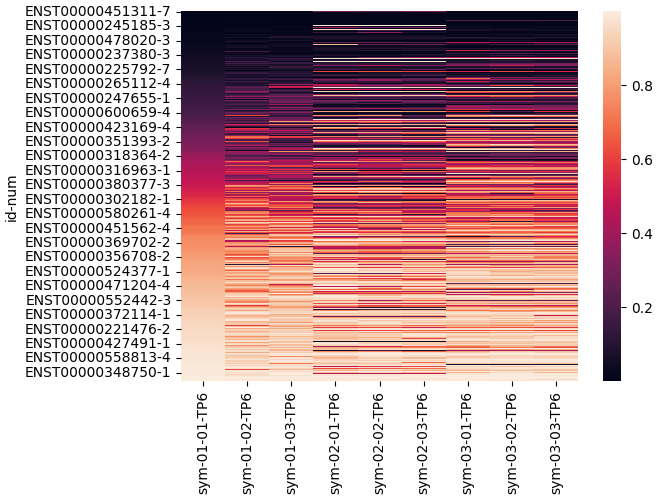

In [92]:
sns.heatmap(gene_ranking.T.loc[:, 'neg', 'score'].T)

<Axes: xlabel='lfc', ylabel='score'>

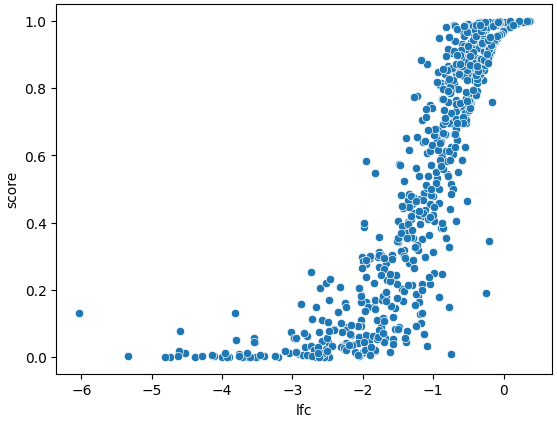

In [93]:
sns.scatterplot(data=gene_ranking.T.loc['sym-03-03-TP6', 'neg', :].T, x='lfc', y='score')

# Target-wise correlation across guides / Outlier detection

In [24]:
# df = pd.read_csv(Path(config['TEMPDIR']) / 'pooled_screen_1/pooled_screen_1_counts.csv', index_col=0)
df = pd.read_csv(path / 'pooled_screen_1_counts.csv', index_col=0)

sample_names = np.sort(df.columns[12:])
pools = ['Sym-pool-1-3', 'Sym-pool-1-1', 'Sym-pool-1-2']
pools = np.sort(pools)
sample_names_wo_pools = [x for x in sample_names if not any([p in x for p in pools])]
controls = [x for x in df.index if 'control' in x.lower()]

# First I normalize for seq-depth by bringing all NT guides to the same count
target = df.loc[controls, sample_names_wo_pools].mean().mean()  # mean of NTs in control
ist = df.loc[controls, sample_names].mean()  # mean of NTs in all
norm_factor = target / ist  # make all NT mean counts equal to those in control
ndf = df.loc[:, sample_names] * norm_factor  # normalize

# Foldchange to Pool after seq-depth normalization based on NT depth
fc = (ndf.loc[:, sample_names].T / ndf.loc[:, pools].mean(axis=1)).T  # normalize to control (pools)
l2fc = np.log2(fc)
l2fc[l2fc==-np.infty] = None

In [25]:
guide_groupby = 'Transcript_ID'  # 'Gene'

# For each gene / transcript, compute the correlation across guides targeting the same gene.
# NOTE: might make sense to get averages over replicates before outlier detection.
tempdf = l2fc.copy()
tempdf[guide_groupby] = df[guide_groupby]
guide_stats = {}
correlations = {}
for group in tqdm(tempdf[guide_groupby].unique()):
    # get the guide counts for this gene
    ldf = tempdf.loc[tempdf[guide_groupby]==group, :].drop(guide_groupby, axis=1)
    # compute the correlation across guides
    corr = ldf.T.corr()
    correlation = np.mean(corr.values)
    average_lfc = np.nanmean(ldf.values)
    absmean = np.abs(ldf.mean(axis=1))
    highest_lfc = np.max(absmean)
    second_highest_lfc = np.partition(absmean, -2)[-2] if len(absmean) > 1 else np.nan
    lowest_lfc = np.min(absmean)
    second_lowest_lfc = np.partition(absmean, 1)[1] if len(absmean) > 1 else np.nan
    std = np.std(ldf.mean(axis=1))
    highest_zscore = (highest_lfc - average_lfc) / std
    second_highest_zscore = (second_highest_lfc - average_lfc) / std
    guide_stats[group] = {'correlation': correlation, 'average_lfc': average_lfc, 
                          'highest_lfc': highest_lfc, 'second_highest_lfc': second_highest_lfc,
                          'lowest_lfc': lowest_lfc, 'second_lowest_lfc': second_lowest_lfc,
                          'std': std, 'highest_zscore': highest_zscore,
                            'second_highest_zscore': second_highest_zscore
                          }
    correlations[group] = corr

  0%|          | 0/944 [00:00<?, ?it/s]

In [27]:
guide_stats_df = pd.DataFrame(guide_stats).T.sort_values('correlation', ascending=False)
guide_stats_df

,correlation,average_lfc,highest_lfc,second_highest_lfc,lowest_lfc,second_lowest_lfc,std,highest_zscore,second_highest_zscore
rc_000078,1.000000,0.034937,0.034937,NaN,0.034937,NaN,0.000000,NaN,NaN
rc_000079,1.000000,0.317574,0.317574,NaN,0.317574,NaN,0.000000,NaN,NaN
rc_000110,1.000000,0.050271,0.050271,NaN,0.050271,NaN,0.000000,NaN,NaN
rc_000121,1.000000,-0.362192,0.362192,NaN,0.362192,NaN,0.000000,inf,NaN
rc_000138,1.000000,0.031147,0.031147,NaN,0.031147,NaN,0.000000,NaN,NaN
...,...,...,...,...,...,...,...,...,...
ENST00000566912,0.073637,0.081879,0.182193,0.167449,0.000339,0.042049,0.066301,1.513001,1.290616
ENST00000556013,0.072031,0.084057,0.231122,0.183031,0.004170,0.021875,0.082129,1.790657,1.205101
ENST00000413510,0.068768,-0.000358,0.226595,0.169196,0.012840,0.016178,0.112682,2.014106,1.504717
ENST00000564492,0.063921,0.016533,0.164037,0.128336,0.010954,0.045205,0.095558,1.543604,1.169993


<Axes: xlabel='highest_zscore', ylabel='Count'>

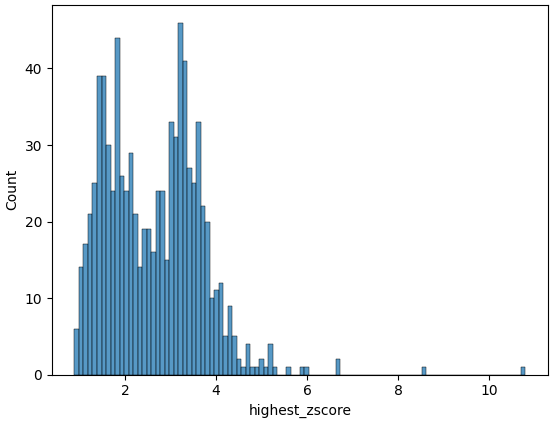

In [28]:
sns.histplot(guide_stats_df['highest_zscore'], bins=100)

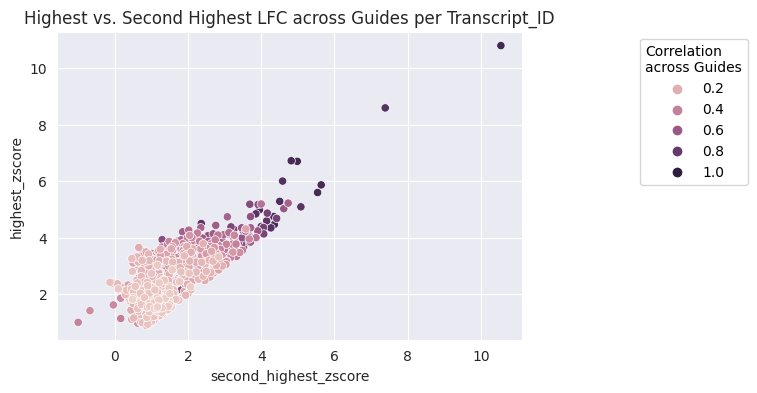

In [40]:
with sns.axes_style('darkgrid'):
    fig, ax = pl.subplots(figsize=(6,4))
sns.scatterplot(data=guide_stats_df, x='second_highest_zscore', y='highest_zscore', hue='correlation', ax=ax)
pl.title(f'Highest vs. Second Highest LFC across Guides per {guide_groupby}')
pl.legend(title='Correlation\nacross Guides')
sns.move_legend(ax, "upper right", bbox_to_anchor=(1.5, 1))
pl.show()

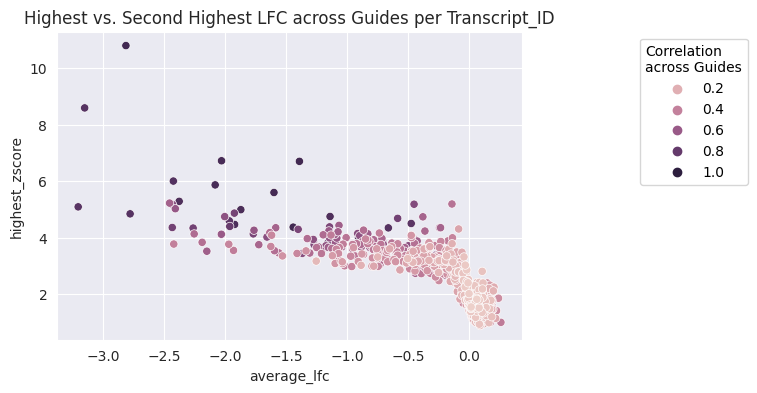

In [41]:
with sns.axes_style('darkgrid'):
    fig, ax = pl.subplots(figsize=(6,4))
sns.scatterplot(data=guide_stats_df, x='average_lfc', y='highest_zscore', hue='correlation', ax=ax)
pl.title(f'Highest vs. Second Highest LFC across Guides per {guide_groupby}')
pl.legend(title='Correlation\nacross Guides')
sns.move_legend(ax, "upper right", bbox_to_anchor=(1.5, 1))
pl.show()

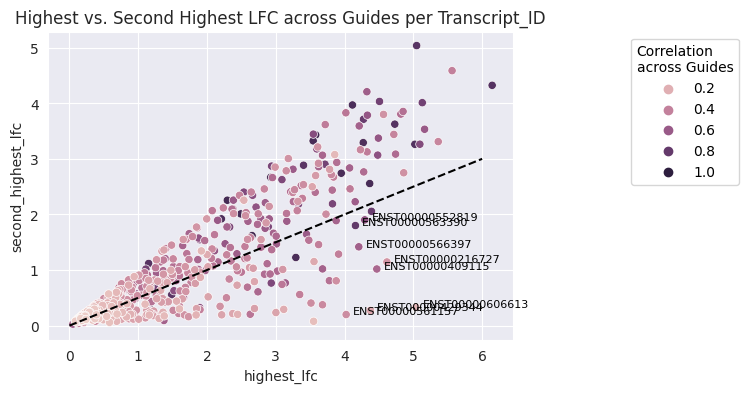

In [19]:
with sns.axes_style('darkgrid'):
    fig, ax = pl.subplots(figsize=(6,4))
sns.scatterplot(data=guide_stats_df, x='highest_lfc', y='second_highest_lfc', hue='correlation', ax=ax)
pl.title(f'Highest vs. Second Highest LFC across Guides per {guide_groupby}')
pl.plot([0, 6], [0, 6 / 2], 'k--')
pl.legend(title='Correlation\nacross Guides')
mask = (guide_stats_df.highest_lfc>4) & (guide_stats_df.second_highest_lfc<2)
# annotate the outliers
for gene, row in guide_stats_df[mask].iterrows():
    ax.text(row.highest_lfc+0.1, row.second_highest_lfc, gene, fontsize=8)
sns.move_legend(ax, "upper right", bbox_to_anchor=(1.5, 1))
pl.show()

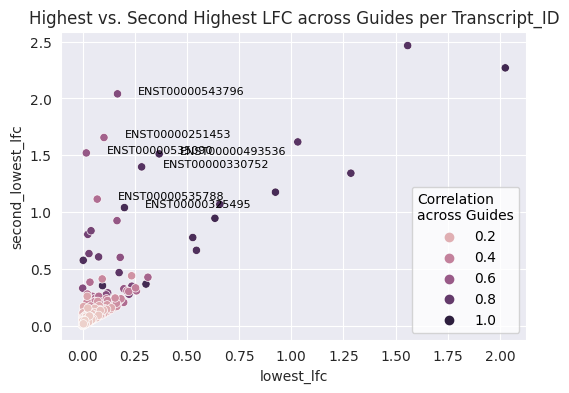

In [18]:
with sns.axes_style('darkgrid'):
    fig, ax = pl.subplots(figsize=(6,4))
sns.scatterplot(data=guide_stats_df, x='lowest_lfc', y='second_lowest_lfc', hue='correlation', ax=ax)
pl.title(f'Highest vs. Second Highest LFC across Guides per {guide_groupby}')
pl.legend(title='Correlation\nacross Guides')
mask = (guide_stats_df.lowest_lfc<0.5) & (guide_stats_df.second_lowest_lfc>1)
# annotate the outliers
for gene, row in guide_stats_df[mask].iterrows():
    ax.text(row.lowest_lfc+0.1, row.second_lowest_lfc, gene, fontsize=8)

pl.show()

In [8]:
# some genes with potential single-guide outliers
guide_stats_df[mask]

,correlation,average_lfc,highest_lfc,second_highest_lfc,lowest_lfc,second_lowest_lfc
ENST00000325495,0.904155,-1.599481,2.295563,2.255703,0.200700,1.038533
ENST00000493536,0.900026,-2.029545,4.365579,2.556017,0.367248,1.511310
ENST00000330752,0.841750,-2.778945,6.145859,4.323246,0.283161,1.396774
ENST00000543796,0.682751,-2.431491,5.094721,3.263548,0.167461,2.039368
ENST00000535090,0.614723,-2.408398,4.332033,3.785553,0.018036,1.519630
ENST00000251453,0.558339,-2.455316,4.212908,3.592632,0.102725,1.655190
ENST00000535788,0.493394,-1.305908,2.874852,1.113261,0.070390,1.113261


In [9]:
df[df.Transcript_ID=='ENST00000563390']

,Transcript_ID,ensembl_gene_id,Gene,transcript_biotype,GuideName,GuideSeq,MatchPos,Guide_Score,Region,transcript_length,...,sym-03-02-TP3,sym-03-02-TP4,sym-03-02-TP5,sym-03-02-TP6,sym-03-03-TP1,sym-03-03-TP2,sym-03-03-TP3,sym-03-03-TP4,sym-03-03-TP5,sym-03-03-TP6
unique_guide_name,,,,,,,,,,,,,,,,,,,,,
RPS15A_ENST00000563390_324,ENST00000563390,ENSG00000134419,RPS15A,protein_coding,crRNA302:302-324,TGCACGTCAAATCTGGGGCTGAT,324.0,0.980438,CDS,525.0,...,1569,1897,1389,1543,2101,1608,1554,1647,1219,1131
RPS15A_ENST00000563390_325,ENST00000563390,ENSG00000134419,RPS15A,protein_coding,crRNA303:303-325,TTGCACGTCAAATCTGGGGCTGA,325.0,0.944003,CDS,525.0,...,795,840,693,638,1042,806,748,873,644,600
RPS15A_ENST00000563390_340,ENST00000563390,ENSG00000134419,RPS15A,protein_coding,crRNA318:318-340,TTCCAGGTCTTTGAGTTGCACGT,340.0,0.993995,CDS,525.0,...,183,178,111,64,836,185,111,82,68,56
RPS15A_ENST00000563390_342,ENST00000563390,ENSG00000134419,RPS15A,protein_coding,crRNA320:320-342,TTTTCCAGGTCTTTGAGTTGCAC,342.0,0.933769,CDS,525.0,...,1326,1559,1422,1503,1561,1339,1437,1715,1247,1498
RPS15A_ENST00000563390_424,ENST00000563390,ENSG00000134419,RPS15A,protein_coding,crRNA383:402-424,TTCTTCATGGTCCATGATGCCAG,424.0,0.962256,CDS,525.0,...,701,754,713,574,1480,767,647,628,459,545
RPS15A_ENST00000563390_522,ENST00000563390,ENSG00000134419,RPS15A,protein_coding,crRNA478:500-522,AGCACCAGAGTCCATGAGGCATT,522.0,0.952233,UTR3,525.0,...,1190,1205,959,816,1433,1293,1094,1111,799,859
RPS15A_ENST00000563390_523,ENST00000563390,ENSG00000134419,RPS15A,protein_coding,crRNA479:501-523,AAGCACCAGAGTCCATGAGGCAT,523.0,0.990817,UTR3,525.0,...,1375,1483,1404,1375,1676,1245,1410,1677,1089,1259


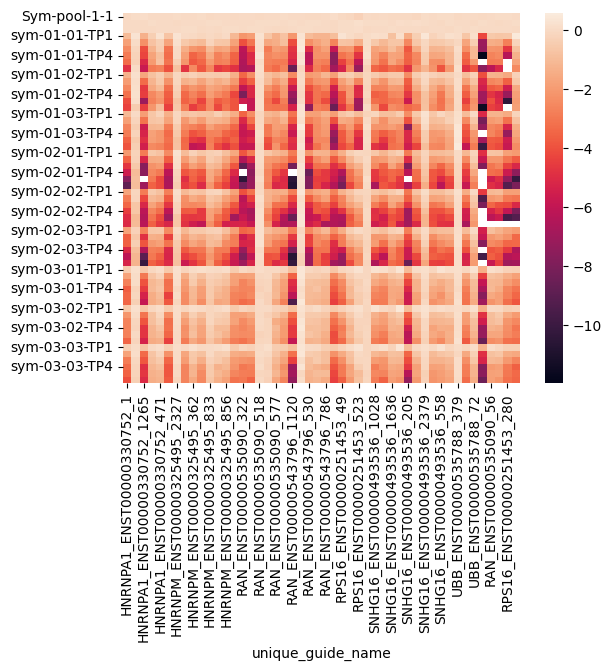

In [10]:
selection = guide_stats_df[mask].index
guides = df[df[guide_groupby].isin(selection)].index

data = l2fc.loc[guides].T

# annotate with pyComplexHeatmap
sns.heatmap(data)
pl.show()

<Axes: ylabel='unique_guide_name'>

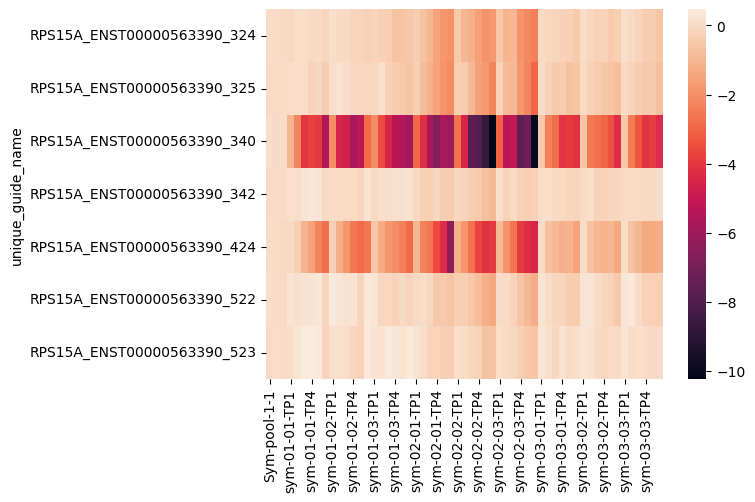

In [11]:
# great example for an outlier guide:
sns.heatmap(l2fc.loc[l2fc.index.str.contains('ENST00000563390'), :])

<Axes: ylabel='unique_guide_name'>

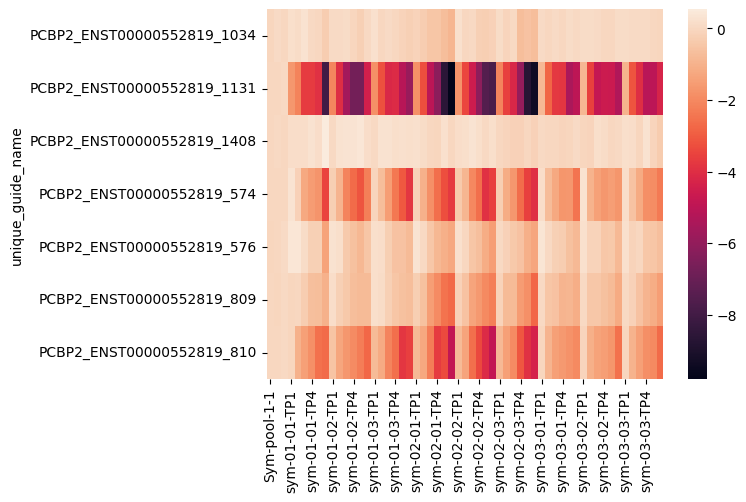

In [12]:
# great example for an outlier guide:
sns.heatmap(l2fc.loc[l2fc.index.str.contains('ENST00000552819'), :])

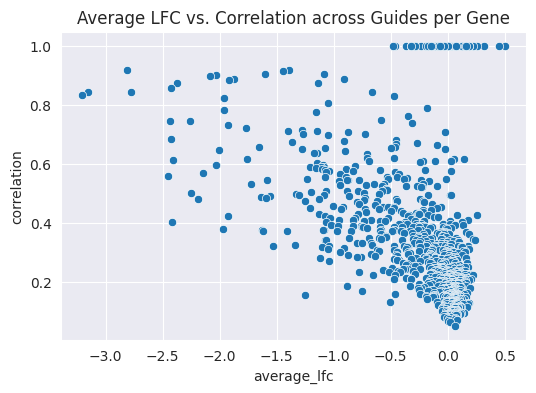

In [13]:
with sns.axes_style('darkgrid'):
    fig, ax = pl.subplots(figsize=(6,4))
sns.scatterplot(data=guide_stats_df, x='average_lfc', y='correlation')
pl.title('Average LFC vs. Correlation across Guides per Gene')
pl.show()

In [14]:
# could I use deseq to analyse this? I don't think so, I am looking for outlier detection...

In [15]:
ldf

,Sym-pool-1-1,Sym-pool-1-2,Sym-pool-1-3,sym-01-01-TP1,sym-01-01-TP2,sym-01-01-TP3,sym-01-01-TP4,sym-01-01-TP5,sym-01-01-TP6,sym-01-02-TP1,...,sym-03-02-TP3,sym-03-02-TP4,sym-03-02-TP5,sym-03-02-TP6,sym-03-03-TP1,sym-03-03-TP2,sym-03-03-TP3,sym-03-03-TP4,sym-03-03-TP5,sym-03-03-TP6
unique_guide_name,,,,,,,,,,,,,,,,,,,,,
ZSWIM3_ENST00000255152_1242,0.009880,-0.015187,0.005184,0.364638,0.417351,0.359797,0.274820,0.252852,-0.243349,0.085702,...,0.199894,0.063253,0.368487,0.314602,0.101795,0.165369,0.208941,0.047973,0.157361,0.040312
ZSWIM3_ENST00000255152_1357,-0.038404,-0.000676,0.038067,0.105199,0.203624,0.303042,0.331314,0.284673,-0.107285,-0.166488,...,0.126607,0.034478,0.003867,0.139065,0.031873,-0.020502,-0.119035,0.119387,-0.121404,-0.200486
ZSWIM3_ENST00000255152_164,-0.059158,0.029032,0.028354,0.323026,0.279262,0.522056,0.439393,0.499221,0.275495,-0.008400,...,0.208654,0.181810,0.197862,0.170973,0.190069,0.243116,0.244725,0.218544,0.202481,0.269581
ZSWIM3_ENST00000255152_2431,-0.023360,0.005627,0.017428,0.203692,-0.012461,-0.005766,-0.005312,-0.128262,0.195416,0.019722,...,0.126035,0.209303,0.234824,0.206383,0.057351,-0.027740,0.083453,0.166186,-0.048886,0.014664
ZSWIM3_ENST00000255152_2528,0.003825,-0.015637,0.011675,0.192674,0.307431,0.334450,0.441067,0.465153,0.011080,-0.061146,...,0.089903,-0.035914,-0.052731,-0.072836,0.161837,0.149989,0.096834,0.088599,-0.125292,-0.158753
ZSWIM3_ENST00000255152_32,0.013393,-0.034953,0.020926,-0.056449,0.208550,0.074120,-0.047415,0.042594,-0.502944,-0.172458,...,-0.031528,-0.093006,0.128799,0.003348,0.092109,-0.047353,-0.244074,-0.146657,-0.091725,-0.132397
ZSWIM3_ENST00000255152_665,-0.085300,0.061587,0.019770,0.134589,0.271410,0.072880,0.064636,0.321402,-0.024407,-0.033636,...,-0.034514,-0.009597,0.072734,0.037480,0.166235,0.154062,-0.028170,0.032647,-0.057593,0.026877


# Region Specificity

In [3]:
df = pd.read_csv(Path(config['TEMPDIR']) / 'pooled_screen_1/pooled_screen_1_counts.csv', index_col=0)
# df = pd.read_csv(path / 'pooled_screen_1_counts.csv', index_col=0)

sample_names = np.sort(df.columns[12:])
pools = ['Sym-pool-1-3', 'Sym-pool-1-1', 'Sym-pool-1-2']
pools = np.sort(pools)
sample_names_wo_pools = [x for x in sample_names if not any([p in x for p in pools])]
controls = [x for x in df.index if 'control' in x.lower()]

# First I normalize for seq-depth by bringing all NT guides to the same count
target = df.loc[controls, sample_names_wo_pools].mean().mean()  # mean of NTs in control
ist = df.loc[controls, sample_names].mean()  # mean of NTs in all
norm_factor = target / ist  # make all NT mean counts equal to those in control
ndf = df.loc[:, sample_names] * norm_factor  # normalize

# Foldchange to Pool after seq-depth normalization based on NT depth
fc = (ndf.loc[:, sample_names].T / ndf.loc[:, pools].mean(axis=1)).T  # normalize to control (pools)
l2fc = np.log2(fc)
l2fc[l2fc==-np.infty] = None

In [4]:
L = l2fc.copy()
L['Region'] = df.Region.copy()
L['Gene'] = df.Gene.copy()
# Ignore "Gene_Body" for now. It's mututally exclusive with "CDS" and "5'UTR" and "3'UTR"

mean_l2fc_per_gene_and_region = L.groupby(['Gene', 'Region']).mean().mean(axis=1).unstack()

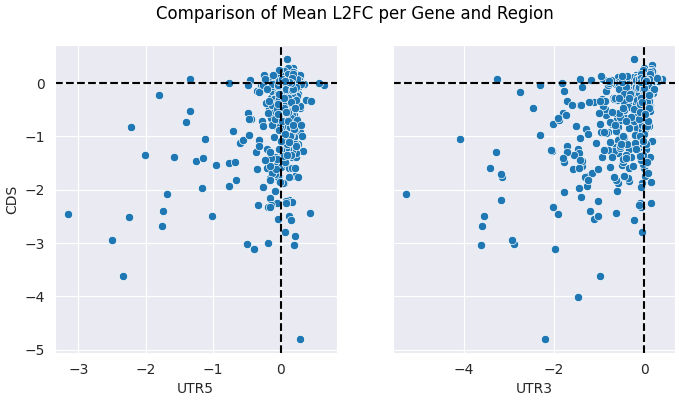

In [5]:
with sns.axes_style('darkgrid'):
    fig, axs = pl.subplots(1, 2, figsize=(4*2,4), sharey=True)
for ax, key in zip(axs, ['UTR5', 'UTR3']):
    sns.scatterplot(data=mean_l2fc_per_gene_and_region, y='CDS', x=key, ax=ax)
    ax.axhline(0, color='k', linestyle='--')
    ax.axvline(0, color='k', linestyle='--')
pl.suptitle('Comparison of Mean L2FC per Gene and Region')
pl.show()

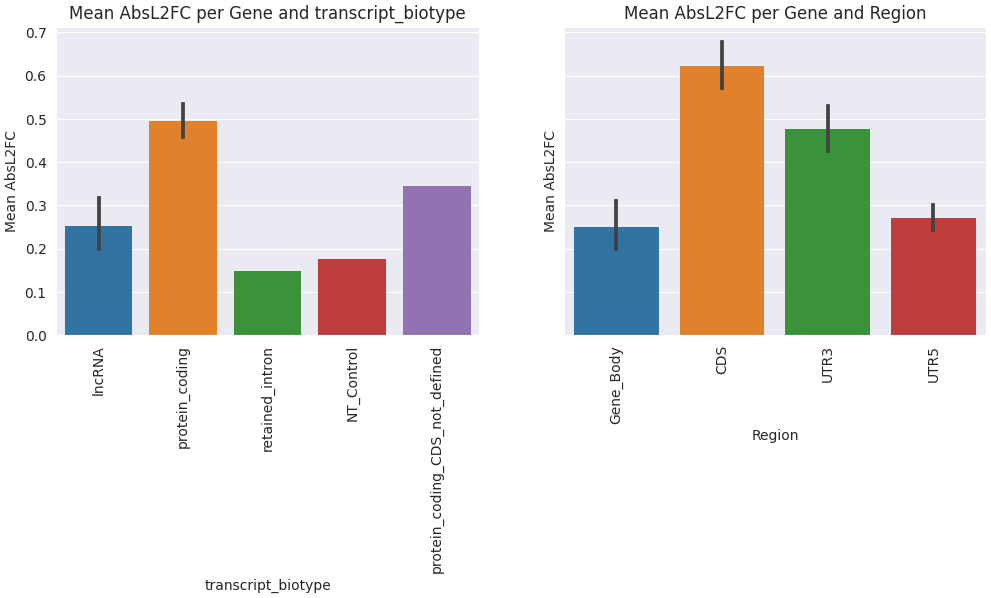

In [43]:
keys = ['transcript_biotype', 'Region']
N = len(keys)

with sns.axes_style('darkgrid'):
    fig, axs = pl.subplots(1, N, figsize=(6*N,4), sharey=True)

for key, ax in zip(keys, axs):
    L = np.abs(l2fc.copy())
    L['Gene'] = df.Gene.copy()
    L[key] = df[key].copy()
    data = L.groupby(['Gene', key]).mean().mean(axis=1).reset_index()
    sns.barplot(data=data, x=key, y=0, ax=ax)
    ax.set_xticklabels(ax.get_xticklabels(), rotation=90)
    ax.set_ylabel('Mean AbsL2FC')
    ax.set_title(f'Mean AbsL2FC per Gene and {key}')
pl.show()


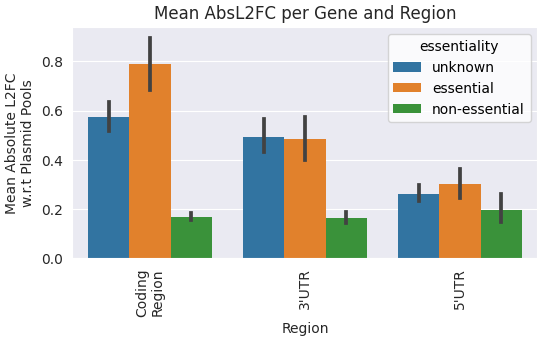

In [7]:
with sns.axes_style('darkgrid'):
    fig, ax = pl.subplots(figsize=(6,3))
L = np.abs(l2fc.copy())
L['Gene'] = df.Gene.copy()
L['Region'] = df['Region'].copy()
L = L[L.Region!='Gene_Body']
L.Region = L.Region.replace({'UTR5': "5'UTR", 'UTR3': "3'UTR", 'CDS': 'Coding\nRegion'})

# Annotate essentiallity based on original Bagel list
essential = pd.read_csv("../resources/bagel_supplement/CEGv2.txt", sep='\t', index_col=0)
non_essential = pd.read_csv("../resources/bagel_supplement/NEGv1.txt", sep='\t', index_col=0)
L['essentiality'] = ['essential' if g in essential.index else 'non-essential' if g in non_essential.index else 'unknown' for g in L.Gene]

data = L.groupby(['Gene', 'essentiality', 'Region']).mean().mean(axis=1).reset_index()
sns.barplot(data=data, x='Region', y=0, ax=ax, order=['Coding\nRegion', "3'UTR", "5'UTR"], hue='essentiality')
ax.set_xticklabels(ax.get_xticklabels(), rotation=90)
ax.set_ylabel('Mean Absolute L2FC\nw.r.t Plasmid Pools')
ax.set_title(f'Mean AbsL2FC per Gene and Region')
pl.savefig('../results/figures/mean_abs_l2fc_per_gene_and_region_by_essentiallity.pdf', bbox_inches='tight', dpi=300)
pl.show()

p-value annotation legend:
      ns: 5.00e-02 < p <= 1.00e+00
       *: 1.00e-02 < p <= 5.00e-02
      **: 1.00e-03 < p <= 1.00e-02
     ***: 1.00e-04 < p <= 1.00e-03
    ****: p <= 1.00e-04

Coding
Region vs. 3'UTR: t-test independent samples, P_val:1.459e-04 t=3.810e+00
5'UTR vs. Coding
Region: t-test independent samples, P_val:4.848e-26 t=-1.082e+01


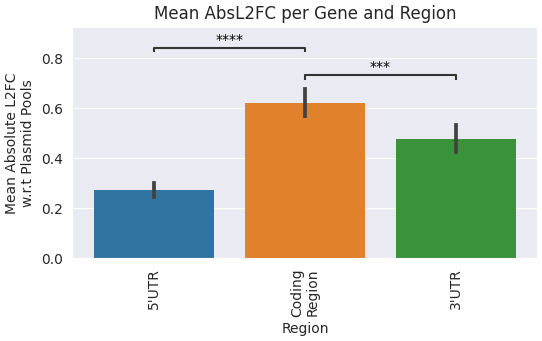

In [9]:
# Plot also without essentiallity
with sns.axes_style('darkgrid'):
    fig, ax = pl.subplots(figsize=(6,3))
data = L.groupby(['Gene', 'Region']).mean().mean(axis=1).reset_index()

sns.barplot(data=data, x='Region', y=0, ax=ax, order=["5'UTR", 'Coding\nRegion', "3'UTR"])
ax.set_xticklabels(ax.get_xticklabels(), rotation=90)
ax.set_ylabel('Mean Absolute L2FC\nw.r.t Plasmid Pools')
ax.set_title(f'Mean AbsL2FC per Gene and Region')
from statannotations.Annotator import Annotator
pairs=[("Coding\nRegion", "3'UTR"), ("Coding\nRegion", "5'UTR")]
annotator = Annotator(ax, pairs, data=data, x='Region', y=0, order=["5'UTR", 'Coding\nRegion', "3'UTR"])
annotator.configure(test='t-test_ind', text_format='star', loc='inside')
annotator.apply_and_annotate()
pl.savefig('../results/figures/mean_abs_l2fc_per_gene_and_region.pdf', bbox_inches='tight', dpi=300)
pl.show()

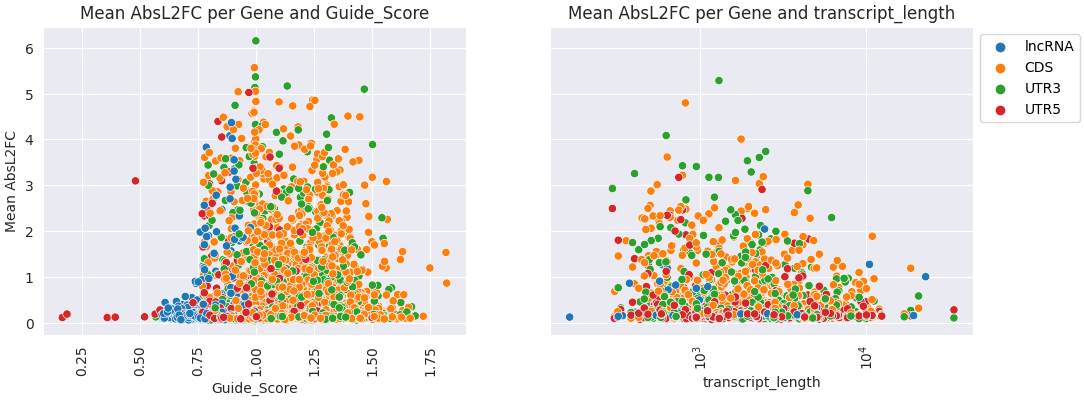

In [44]:
keys = ['Guide_Score', 'transcript_length']
N = len(keys)
hue = 'Region'

with sns.axes_style('darkgrid'):
    fig, axs = pl.subplots(1, N, figsize=(6*N,4), sharey=True)

for key, ax in zip(keys, axs):
    L = np.abs(l2fc.copy())
    L['Gene'] = df.Gene.copy()
    L[key] = df[key].copy()
    L[hue] = df[hue].copy()
    if hue == 'Region':
        L[hue] = L[hue].replace({'Gene_Body': 'lncRNA'})
    data = L.groupby(['Gene', hue, key]).mean().mean(axis=1).reset_index()
    sns.scatterplot(data=data, x=key, y=0, ax=ax, hue=hue)
    ax.set_xticklabels(ax.get_xticklabels(), rotation=90)
    ax.set_ylabel('Mean AbsL2FC')
    ax.set_title(f'Mean AbsL2FC per Gene and {key}')
    if key=='transcript_length':
        ax.set_xscale('log')
    if ax==axs[1]:
        ax.legend(loc='upper left', bbox_to_anchor=(1, 1))
    else:
        ax.get_legend().remove()
pl.show()


In [81]:
df.transcript_biotype

unique_guide_name
AATBC_ENST00000400385_1005            lncRNA
AATBC_ENST00000400385_1562            lncRNA
AATBC_ENST00000400385_1938            lncRNA
AATBC_ENST00000400385_2713            lncRNA
AATBC_ENST00000400385_28              lncRNA
                                   ...      
RPS16_ENST00000251453_280     protein_coding
RPS16_ENST00000251453_300     protein_coding
RPS5_ENST00000196551_431      protein_coding
RPS5_ENST00000196551_574      protein_coding
RPS5_ENST00000196551_68       protein_coding
Name: transcript_biotype, Length: 6225, dtype: object

# Differential transcript depletion (same gene, different transcript)

In [29]:
# Find genes where transcripts showed different reactions
# Can't use BAGEL for this. Will work on L2FC instead.
# Restrict to protein-coding region
sdf = df[df.Region=='CDS'].copy()
multi_transcript_genes = [gene for gene in sdf.Gene.unique() if len(sdf[sdf.Gene == gene].Transcript_ID.unique()) > 1]

In [30]:
filter = pd.read_csv('../results/tables/pooled_screen_1_mageck_filtered_guides_v1.tsv', sep='\t', header=[0,1,2], index_col=0).droplevel(2, axis=1)
is_working = filter.loc[:, ('summary', 'is_working')]
# sdf = sdf.loc[is_working.index]

In [31]:
sdf = sdf[sdf.Gene.isin(multi_transcript_genes)]
L = l2fc.loc[sdf.index, sample_names_wo_pools]

In [32]:
L

,sym-01-01-TP1,sym-01-01-TP2,sym-01-01-TP3,sym-01-01-TP4,sym-01-01-TP5,sym-01-01-TP6,sym-01-02-TP1,sym-01-02-TP2,sym-01-02-TP3,sym-01-02-TP4,...,sym-03-02-TP3,sym-03-02-TP4,sym-03-02-TP5,sym-03-02-TP6,sym-03-03-TP1,sym-03-03-TP2,sym-03-03-TP3,sym-03-03-TP4,sym-03-03-TP5,sym-03-03-TP6
unique_guide_name,,,,,,,,,,,,,,,,,,,,,
ANAPC11_ENST00000344877_202,0.412015,0.369900,0.536509,0.580091,0.308489,-0.108070,0.242893,0.290519,0.045819,-0.035401,...,0.212249,0.095490,0.172924,0.037166,0.216169,0.261061,0.158150,0.190354,-0.155788,-0.109976
ANAPC11_ENST00000344877_204,0.474597,0.362447,0.335433,0.136449,0.027478,0.301345,0.364665,0.317609,0.363202,0.278205,...,0.075000,-0.045905,-0.075150,0.044423,0.294426,0.167683,0.261667,-0.012816,0.102772,0.103529
ANAPC11_ENST00000344877_374,0.201372,-0.037688,-0.050779,-0.031956,0.060283,0.085101,0.001154,-0.054299,0.034638,0.098147,...,0.147123,0.036241,-0.043348,0.008732,0.101639,0.153108,0.074120,0.077000,-0.100733,0.062741
ANAPC11_ENST00000579978_232,0.214941,-0.150430,0.076992,0.081761,0.185460,-0.138536,-0.194746,-0.123923,-0.226552,-0.254744,...,-0.045684,-0.226075,-0.273500,-0.228488,-0.013864,-0.029551,-0.081301,-0.256966,-0.244536,-0.255292
ANAPC11_ENST00000579978_233,-0.110474,0.181127,0.244365,0.283041,0.177209,0.147443,0.198662,0.169761,0.305489,0.171650,...,-0.006661,0.101077,0.130046,0.035998,-0.077720,-0.000240,-0.115191,0.107115,-0.064436,-0.200174
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
ZRANB2_ENST00000370920_541,0.233212,-0.014063,-0.894476,-1.445218,-1.808668,-2.502527,0.023167,-0.303353,-1.184761,-1.396507,...,-0.378122,-0.424553,-0.225600,-0.405982,0.172480,-0.206880,-0.214627,-0.429636,-0.404641,-0.540435
ZRANB2_ENST00000370920_738,0.108466,0.161241,0.244252,0.268561,0.125397,-0.177507,0.038689,-0.058115,-0.092975,-0.090920,...,-0.086082,-0.071181,-0.067710,-0.072547,0.072926,-0.067302,0.248733,-0.070964,-0.018676,0.085130
FBL_ENST00000597224_524,-0.613396,-2.965704,-6.943970,NaN,NaN,-9.709505,-1.496899,-3.964667,-7.497011,-6.704697,...,-2.179622,-2.726729,-2.476917,-2.966255,-0.037557,-1.469564,-2.157222,-3.057713,-3.221471,-3.252916


In [33]:
L['Gene'] = sdf.Gene.copy()
L['Transcript_ID'] = sdf.Transcript_ID.copy()
mL = L.groupby(['Gene', 'Transcript_ID']).mean()
mmL = mL.mean(axis=1).to_frame().sort_values(0, ascending=False)
# annotate the Transcript_ID number of each gene
mmL['Transcript_ID_number'] = mmL.groupby('Gene').cumcount()+1
mmL.set_index('Transcript_ID_number', append=True, inplace=True)
mmL = mmL.reset_index()

In [34]:
mmL

,Gene,Transcript_ID,Transcript_ID_number,0
0,MBD1,ENST00000347968,1,0.340078
1,PCBP4,ENST00000355852,1,0.309204
2,STARD8,ENST00000374597,1,0.253109
3,ATP5F1D,ENST00000215375,1,0.234240
4,PCBP4,ENST00000471622,2,0.218523
...,...,...,...,...
176,PPIA,ENST00000355968,2,-2.614012
177,UBE2I,ENST00000403747,2,-2.647368
178,RNPS1,ENST00000320225,2,-2.655010
179,NUTF2,ENST00000569436,2,-3.367088


In [35]:
# now make a scatterplot where x is number 1 and y is number 2
# first need to pivot the table
pmmL = mmL.pivot(index='Gene', columns='Transcript_ID_number', values=0)

pmmL['min_l2fc'] = pmmL.min(axis=1, skipna=True)
pmmL['max_l2fc'] = pmmL.max(axis=1, skipna=True)

In [36]:
pmmL

Transcript_ID_number,1,2,3,4,min_l2fc,max_l2fc
Gene,,,,,,
ANAPC11,-0.096340,-0.124690,NaN,NaN,-0.124690,-0.096340
ANAPC5,-0.538551,-1.244899,NaN,NaN,-1.244899,-0.538551
ATP5F1D,0.234240,-0.057472,NaN,NaN,-0.057472,0.234240
ATRAID,0.091821,0.009516,NaN,NaN,0.009516,0.091821
ATXN7L3,-0.031660,-0.077083,NaN,NaN,-0.077083,-0.031660
...,...,...,...,...,...,...
VARS2,-0.062155,-0.107240,NaN,NaN,-0.107240,-0.062155
WWP1,-0.186620,-0.859499,NaN,NaN,-0.859499,-0.186620
ZFAND6,0.140269,0.128588,-0.005544,NaN,-0.005544,0.140269


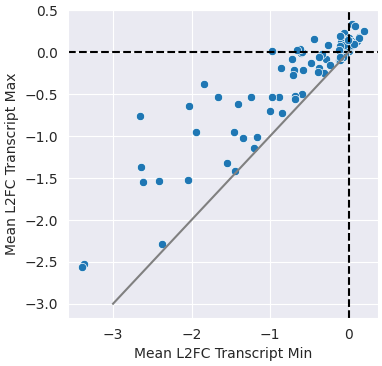

In [37]:
with sns.axes_style('darkgrid'):
    fig, ax = pl.subplots(figsize=(4,4))
sns.scatterplot(data=pmmL, x='min_l2fc', y='max_l2fc', ax=ax)
pl.xlabel('Mean L2FC Transcript Min')
pl.ylabel('Mean L2FC Transcript Max')
pl.axhline(0, color='k', linestyle='--')
pl.axvline(0, color='k', linestyle='--')
# draw diagonal
pl.plot([-3, 0], [-3, 0], 'grey')
pl.show()

In [38]:
hits = (pmmL.max_l2fc - pmmL.min_l2fc).sort_values(ascending=False).index[:10]
dat = mL.loc[hits]

<Axes: ylabel='Gene-Transcript_ID'>

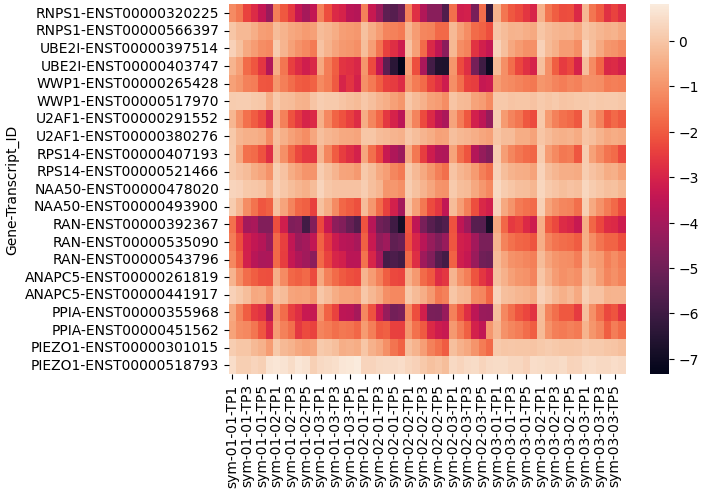

In [209]:
sns.heatmap(dat)

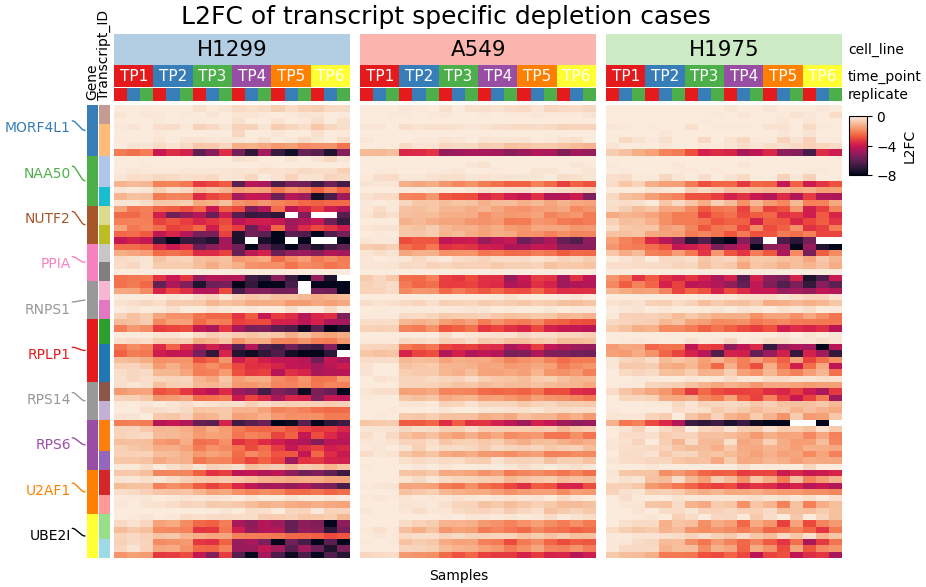

In [42]:
# correlation between samples
cell_line = pd.Series({x: int(x.split('-')[1]) for x in sample_names_wo_pools}).replace(cell_line_dict)
replicate = pd.Series({x: x.split('-')[2] for x in sample_names_wo_pools})
time_point = pd.Series({x: x.split('-')[3].split('_')[0] for x in sample_names_wo_pools})
col_order = pd.concat([cell_line, replicate, time_point], axis=1).sort_values([0, 2, 1]).index  # sort by time before replicate

data = l2fc.loc[df.Gene.isin(hits) & (df.Region == 'CDS'), col_order].sort_index()

top_ha = pch.HeatmapAnnotation(
    cell_line=pch.anno_simple(cell_line.loc[col_order], add_text=True, height=7, cmap='Pastel1'),
    time_point=pch.anno_simple(time_point.loc[col_order], add_text=True, height=5, cmap='Set1'),
    replicate=pch.anno_simple(replicate.loc[col_order], add_text=False),
    verbose=0, axis=1, plot_legend=False
)

left_ha = pch.HeatmapAnnotation(
    label=pch.anno_label(df.loc[data.index, 'Gene'], merge=True, extend=True),
    Gene=pch.anno_simple(df.loc[data.index, 'Gene']),
    Transcript_ID=pch.anno_simple(df.loc[data.index, 'Transcript_ID']),
    verbose=0, axis=0, plot_legend=False
)

pl.figure(figsize=(10, 6))
cm = pch.ClusterMapPlotter(
    data=data, top_annotation=top_ha, left_annotation=left_ha,
    row_cluster=False, col_cluster=False,
    legend_gap=7, vmax=0, vmin=-8,
    col_split=cell_line.loc[col_order], col_split_gap=2.5,
    rasterized=True, cmap='rocket',
    legend_kws=dict(label='L2FC'),
    xlabel="Samples", ylabel='', legend_hpad=0,
    verbose=0
)
pl.suptitle("L2FC of transcript specific depletion cases", y=0.93, fontsize=18)
pl.savefig('../results/figures/l2fc_transcript_specific_depletion_heatmap.pdf', dpi=300, bbox_inches='tight')
pl.show()

# Differences between cell lines / samples

In [109]:
df = pd.read_csv(Path(config['TEMPDIR']) / 'pooled_screen_1/pooled_screen_1_counts.csv', index_col=0)

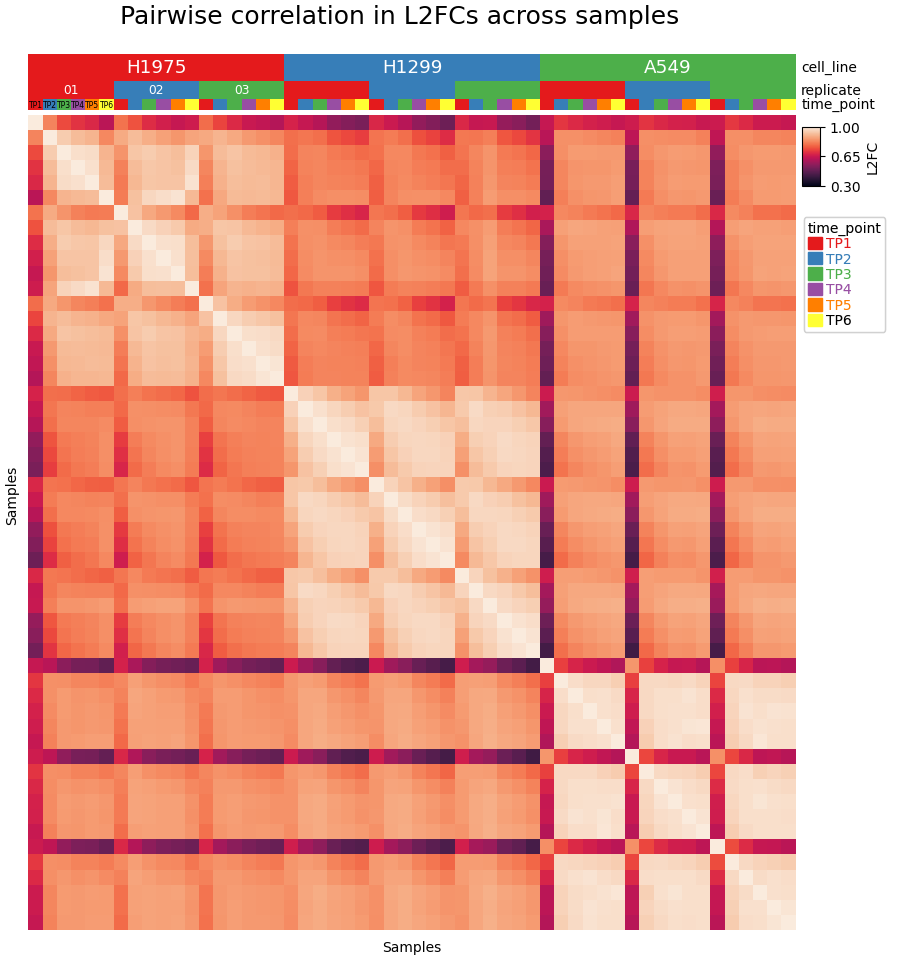

In [110]:
# correlation between samples
data = l2fc.loc[:, sample_names_wo_pools].corr()

cell_line = pd.Series({x: int(x.split('-')[1]) for x in data.columns}).replace(cell_line_dict)
replicate = pd.Series({x: x.split('-')[2] for x in data.columns})
time_point = pd.Series({x: x.split('-')[3].split('_')[0] for x in data.columns})

top_ha = pch.HeatmapAnnotation(
    cell_line=pch.anno_simple(cell_line, add_text=True, height=6, legend=False),
    replicate=pch.anno_simple(replicate, add_text=True, height=4, legend=False),
    time_point=pch.anno_simple(time_point, add_text=True, height=2.5, text_kws={'color': 'black'}),
    verbose=0, axis=1, plot_legend=True
)

pl.figure(figsize=(10, 10))
cm = pch.ClusterMapPlotter(
    data=data, top_annotation=top_ha,
    row_cluster=False, col_cluster=False,
    legend_gap=7, vmin=0.3,
    rasterized=True, cmap='rocket',
    legend_kws=dict(label='L2FC'),
    xlabel="Samples", ylabel='Samples', legend_hpad=0,
    verbose=0
)
pl.suptitle("Pairwise correlation in L2FCs across samples", y=0.93, fontsize=18)
pl.savefig('../results/figures/pairwise_correlation_heatmap.pdf', dpi=300, bbox_inches='tight')
pl.show()

In [111]:
# Use results from BAGEL2 to detect cell line specific essential genes
bagel = pd.read_table('../results/tables/pooled_screen_1_counts_bagel_pr_gene.tsv', index_col=0, header=[0,1,2])
sdf = bagel.xs('BF', level=2, axis=1).xs('alltimes', level=1, axis=1)

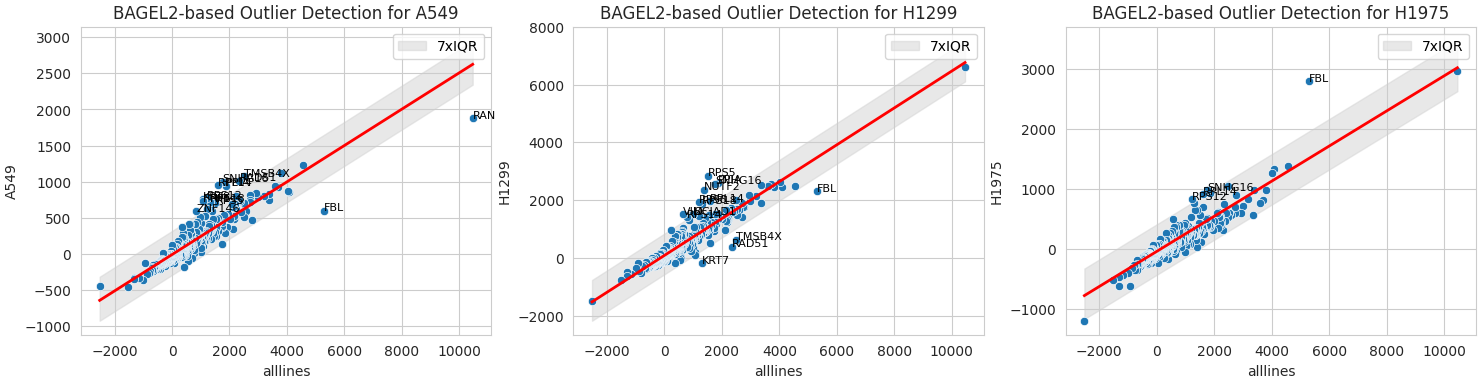

In [112]:
from sklearn import linear_model

outlier_genes_up = {}
outlier_genes_down = {}
with sns.axes_style('whitegrid'):
    fig, axs = pl.subplots(1, 3, figsize=(6 * 3,4))

for ax, line in zip(axs, ['A549', 'H1299', 'H1975']):
    xkey = 'alllines'
    ykey = line

    # Data #
    x, y = sdf[xkey].values.reshape(-1, 1), sdf[ykey].values.reshape(-1, 1)
    # Make fit #
    regr = linear_model.LinearRegression()
    regr.fit(x, y)
    y_pred = regr.predict(x)

    # Detect outliers #
    residuals = y - y_pred
    IQR = np.percentile(residuals, 75) - np.percentile(residuals, 25)
    Q1 = np.percentile(residuals, 25)
    Q3 = np.percentile(residuals, 75)
    factor = 7 # width of the IQR zone for outlier detection
    mask_up = np.ravel(((residuals > Q3 + factor*IQR)) & (y_pred > 0))
    mask_down = np.ravel(((residuals < Q1 - factor*IQR)) & (y_pred > 0))
    mask = mask_up | mask_down
    outlier_genes_up[line] = sdf.index[mask_up].tolist()
    outlier_genes_down[line] = sdf.index[mask_down].tolist()

    # Plot #
    sns.scatterplot(data=sdf, x=xkey, y=ykey, ax=ax)
    ax.plot(x, y_pred, color='red', linewidth=2)
    for i, txt in enumerate(sdf.index[mask]):
        ax.annotate(txt, (x[mask][i], y[mask][i]), fontsize=8)
    ax.fill_between(np.ravel(x), np.ravel(y_pred - Q1 - factor*IQR), np.ravel(y_pred + Q3 + factor*IQR), 
                    color='lightgray', alpha=0.5, zorder=-1, label=f'{factor}xIQR')
    ax.set_title(f'BAGEL2-based Outlier Detection for {line}')
    ax.legend()
pl.show()

In [113]:
# this is a dict of lists of genes that are outliers in the respective cell lines
# make it a dataframe where index is gene and columns are cell lines
index = list(set(outlier_genes_up['A549'] + outlier_genes_up['H1299'] + outlier_genes_up['H1975'] + \
                 outlier_genes_down['A549'] + outlier_genes_down['H1299'] + outlier_genes_down['H1975']
                 ))
outlier_df = pd.DataFrame(0, index=index, columns=['A549', 'H1299', 'H1975'])
for line in ['A549', 'H1299', 'H1975']:
    outlier_df.loc[outlier_genes_up[line], line] = 1
    outlier_df.loc[outlier_genes_down[line], line] = -1
# outlier_df is per gene; make per guide
# is_outlier_guide = pd.DataFrame({guide: outlier_df.loc[gene] for guide, gene in zip(df.index, df.Gene) if gene in outlier_df.index}).T.astype(str)
is_outlier_guide = pd.DataFrame({guide: outlier_df.loc[gene] for guide, gene in zip(df.index, df.Gene) if gene in outlier_df.index}).T

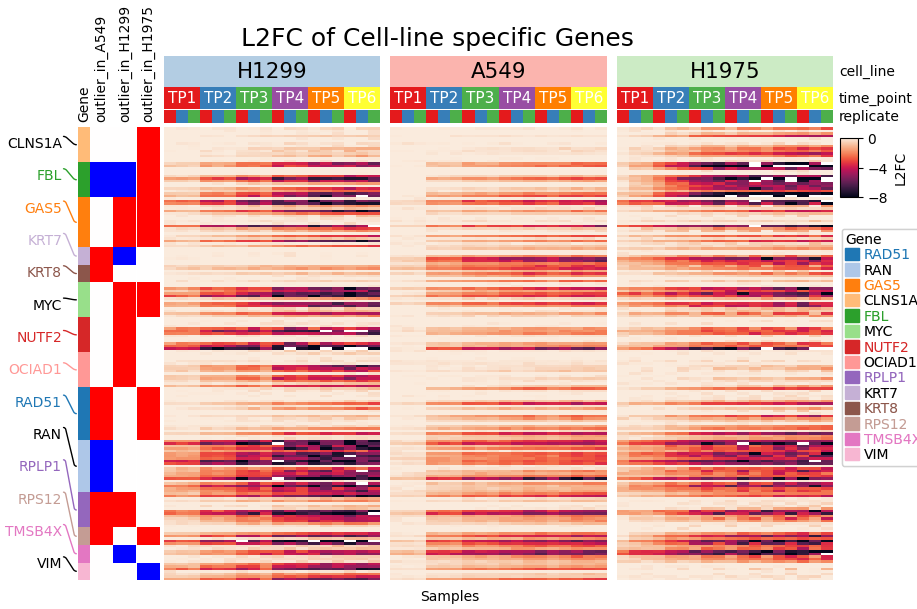

In [150]:
# correlation between samples
data = l2fc.loc[df.Gene.isin(index), sample_names_wo_pools].sort_index()

cell_line = pd.Series({x: int(x.split('-')[1]) for x in data.columns}).replace(cell_line_dict)
replicate = pd.Series({x: x.split('-')[2] for x in data.columns})
time_point = pd.Series({x: x.split('-')[3].split('_')[0] for x in data.columns})
col_order = pd.concat([cell_line, replicate, time_point], axis=1).sort_values([0, 2, 1]).index  # sort by time before replicate

data = data.loc[:, col_order]

top_ha = pch.HeatmapAnnotation(
    cell_line=pch.anno_simple(cell_line.loc[col_order], add_text=True, height=7, cmap='Pastel1'),
    time_point=pch.anno_simple(time_point.loc[col_order], add_text=True, height=5, cmap='Set1'),
    replicate=pch.anno_simple(replicate.loc[col_order], add_text=False),
    verbose=0, axis=1, plot_legend=False
)

kwargs = dict(height=6, cmap='bwr', legend=False)
left_ha = pch.HeatmapAnnotation(
    label=pch.anno_label(df.loc[data.index, 'Gene'], merge=True, extend=True),
    Gene=pch.anno_simple(df.loc[data.index, 'Gene']),
    outlier_in_A549=pch.anno_simple(is_outlier_guide['A549'], **kwargs),
    outlier_in_H1299=pch.anno_simple(is_outlier_guide['H1299'], **kwargs),
    outlier_in_H1975=pch.anno_simple(is_outlier_guide['H1975'], **kwargs),
    verbose=0, axis=0, plot_legend=True
)

pl.figure(figsize=(10, 6))
cm = pch.ClusterMapPlotter(
    data=data, top_annotation=top_ha, left_annotation=left_ha,
    row_cluster=False, col_cluster=False,
    legend_gap=7, vmax=0, vmin=-8,
    col_split=cell_line.loc[col_order], col_split_gap=2.5,
    rasterized=True, cmap='rocket',
    legend_kws=dict(label='L2FC'),
    xlabel="Samples", ylabel='', legend_hpad=0,
    verbose=0
)
pl.suptitle("L2FC of Cell-line specific Genes", y=0.93, fontsize=18)
pl.show()

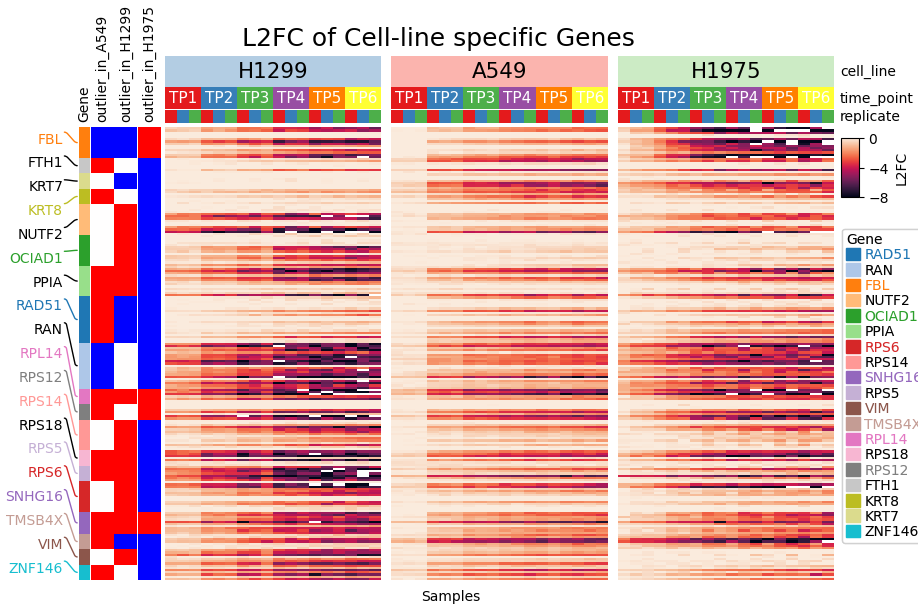

In [116]:
# correlation between samples
data = l2fc.loc[df.Gene.isin(index), sample_names_wo_pools].sort_index()

cell_line = pd.Series({x: int(x.split('-')[1]) for x in data.columns}).replace(cell_line_dict)
replicate = pd.Series({x: x.split('-')[2] for x in data.columns})
time_point = pd.Series({x: x.split('-')[3].split('_')[0] for x in data.columns})
col_order = pd.concat([cell_line, replicate, time_point], axis=1).sort_values([0, 2, 1]).index  # sort by time before replicate

data = data.loc[:, col_order]

top_ha = pch.HeatmapAnnotation(
    cell_line=pch.anno_simple(cell_line.loc[col_order], add_text=True, height=7, cmap='Pastel1'),
    time_point=pch.anno_simple(time_point.loc[col_order], add_text=True, height=5, cmap='Set1'),
    replicate=pch.anno_simple(replicate.loc[col_order], add_text=False),
    verbose=0, axis=1, plot_legend=False
)

kwargs = dict(height=6, cmap='bwr', legend=False)
left_ha = pch.HeatmapAnnotation(
    label=pch.anno_label(df.loc[data.index, 'Gene'], merge=True, extend=True),
    Gene=pch.anno_simple(df.loc[data.index, 'Gene']),
    outlier_in_A549=pch.anno_simple(is_outlier_guide['A549'], **kwargs),
    outlier_in_H1299=pch.anno_simple(is_outlier_guide['H1299'], **kwargs),
    outlier_in_H1975=pch.anno_simple(is_outlier_guide['H1975'], **kwargs),
    verbose=0, axis=0, plot_legend=True
)

pl.figure(figsize=(10, 6))
cm = pch.ClusterMapPlotter(
    data=data, top_annotation=top_ha, left_annotation=left_ha,
    row_cluster=False, col_cluster=False,
    legend_gap=7, vmax=0, vmin=-8,
    col_split=cell_line.loc[col_order], col_split_gap=2.5,
    rasterized=True, cmap='rocket',
    legend_kws=dict(label='L2FC'),
    xlabel="Samples", ylabel='', legend_hpad=0,
    verbose=0
)
pl.suptitle("L2FC of Cell-line specific Genes", y=0.93, fontsize=18)
pl.show()